# Recreating Rehman, Shafi & Wickman (2009)

## "Hybrid Inflation Revisited in Light of WMAP5"
### arXiv:0901.4345, Phys. Rev. D 79, 103503

This notebook implements a step-by-step reconstruction of the paper's key results following the guide's modular structure.

**Units:** Reduced Planck mass $M_P = 1$ throughout (field values, masses, and $V^{1/4}$ quoted in units of $M_P = 2.435 \times 10^{18}$ GeV unless stated otherwise).

In [1]:
#importing libraries & setting units
import numpy as np
from scipy.integrate import quad
from scipy.optimize import brentq, fsolve

#Mp_GeV and DeltaR are defined once here, before their first use; fsolve import added for the full-scan solver]
Mp = 1.0 #reduced Planck mass, working units
Mp_GeV = 2.435e18 #reduced Planck mass in GeV, for unit conversion
DeltaR = 4.91e-5 #WMAP5 curvature-perturbation amplitude Delta_R(k0 = 0.002/Mpc), paper text after Eq. 6

## Stage 1: Slow-Roll Formalism Derivations

**GOAL:** Verify the slow-roll formalism on a toy potential $V(\phi) = \frac{1}{2}m^2\phi^2$ and confirm the known result $n_s \approx 1 - 2/N$ for large $N$. (results pasted in google doc)

**Derivation:**

For $V = \frac{1}{2}m^2\phi^2$:

- $\epsilon(\phi) = \frac{M_P^2}{2}\left(\frac{V'}{V}\right)^2 = \frac{2M_P^2}{\phi^2}$
- $\eta(\phi) = M_P^2\frac{V''}{V} = \frac{2M_P^2}{\phi^2}$
- $N(\phi) = \frac{1}{M_P^2}\int_{\phi_{\text{end}}}^{\phi} \frac{V}{V'} d\phi' = \frac{\phi^2 - \phi_{\text{end}}^2}{4M_P^2}$
- $\phi_{\text{end}}$ from $\epsilon(\phi_{\text{end}}) = 1 \Rightarrow \phi_{\text{end}} = \sqrt{2}M_P$
- $n_s = 1 - 6\epsilon + 2\eta = 1 - \frac{8M_P^2}{\phi^2} = 1 - \frac{2}{N} + \mathcal{O}(1/N^2)$

In [2]:
#MODULE 1: slow-roll formalism derivations
def epsilon_toy(phi, m):
    """Slow-roll epsilon for V = 1/2 m^2 phi^2, computed analytically:
    eps = (Mp^2/2)(V'/V)^2 = 2 Mp^2 / phi^2 for this potential (m cancels)."""
    return 2.0 * Mp**2 / phi**2
 
 
def eta_toy(phi, m):
    """Slow-roll eta for V = 1/2 m^2 phi^2: eta = Mp^2 V''/V = 2 Mp^2/phi^2."""
    return 2.0 * Mp**2 / phi**2
 
 
def N_toy_analytic(phi, phi_end):
    """N(phi) = (phi^2 - phi_end^2) / (4 Mp^2) for V = 1/2 m^2 phi^2.
 
    Derivation: N = (1/Mp^2) int_{phi_end}^{phi} V/V' dphi'
              = (1/Mp^2) int phi'/2 dphi' = (phi^2 - phi_end^2)/(4 Mp^2)
    with phi_end defined by epsilon(phi_end) = 1  =>  phi_end = sqrt(2) Mp.
    """
    return (phi**2 - phi_end**2) / (4.0 * Mp**2)
 
 
def phi_of_N_toy(N, phi_end):
    """Invert N(phi) analytically: phi(N) = sqrt(4 Mp^2 N + phi_end^2)."""
    return np.sqrt(4.0 * Mp**2 * N + phi_end**2)
 
 
def ns_toy(N, phi_end):
    """ns(N) for chaotic V=1/2 m^2 phi^2, exact (not just the N->infty limit)."""
    phi = phi_of_N_toy(N, phi_end)
    eps = epsilon_toy(phi, m=1.0)
    eta = eta_toy(phi, m=1.0)
    return 1.0 - 6.0 * eps + 2.0 * eta
 
 
def r_toy(N, phi_end):
    phi = phi_of_N_toy(N, phi_end)
    eps = epsilon_toy(phi, m=1.0)
    return 16.0 * eps
 
 
def module1_sanity_check(verbose=True):
    """Checkpoint 0/1 sanity harness: for large N, ns -> 1 - 2/N."""
    phi_end = np.sqrt(2.0) * Mp
    results = {}
    for N in [50, 60]:
        ns_exact = ns_toy(N, phi_end)
        ns_approx = 1.0 - 2.0 / N
        r_exact = r_toy(N, phi_end)
        results[N] = dict(ns_exact=ns_exact, ns_approx=ns_approx, r=r_exact)
        if verbose:
            print(f"N={N}: ns(exact)={ns_exact:.4f}  ns(1-2/N approx)={ns_approx:.4f}"
                  f"  r={r_exact:.4f}")
    return results

## Stage 2: Tree-Level Hybrid Potential and Critical Field [Uses Hybrid-inflation potential (Linde 1994; Dvali, Shafi & Schaefer 1994)]

**GOAL:** Define the tree-level hybrid inflation potential and compute the critical field $\phi_c$ where the $S=0$ (waterfall field) valley becomes unstable.

**The Standard Hybrid Inflation Potential:**

$$V(\phi, S) = \frac{\kappa}{4}(S^2 - M^2)^2 + \frac{1}{2}m^2\phi^2 + \frac{1}{2}g^2\phi^2 S^2$$

where:
- $\phi$: gauge-singlet inflaton
- $S$: "waterfall" field charged under the broken symmetry (the paper calls it $\chi$, with $\chi = 2S$)
- $M$: symmetry-breaking scale (sets overall inflationary energy density $\sim \kappa M^4/4$)
- $g$: "hybrid" coupling tying $\phi$ to $S$
- $m$: inflaton soft mass

**Relation to the paper's Eq. 1:** substituting $\chi = 2S$ into $\kappa_p^2(M^2-\chi^2/4)^2 + \lambda^2\chi^2\phi^2/4$ gives $\kappa_p^2 (M^2-S^2)^2 + \lambda^2 S^2\phi^2$, so
$$\kappa_p = \frac{\sqrt{\kappa}}{2}, \qquad \lambda = \frac{g}{\sqrt{2}}, \qquad V_0 = \kappa_p^2 M^4 = \frac{\kappa}{4}M^4$$
[#fixed: the conversion between the notebook couplings $(\kappa, g)$ and the paper's $(\kappa_p, \lambda)$ is stated explicitly and checked numerically in Module 2]

**Critical Field:** Along the $S=0$ valley, the effective mass-squared of $S$ is:

$$m_S^2(\phi) = \frac{\partial^2 V}{\partial S^2}\bigg|_{S=0} = -\kappa M^2 + g^2\phi^2$$

The valley becomes unstable when $m_S^2(\phi_c) = 0$, giving:

$$\phi_c = \frac{\sqrt{\kappa}M}{g} = \frac{\sqrt{2}\,\kappa_p M}{\lambda}$$

**Tree-Level Single-Field Potential:** Along $S=0$:

$$V_0(\phi) = \frac{\kappa}{4}M^4 + \frac{1}{2}m^2\phi^2$$

which is nearly flat (the "hybrid plateau") with a small $m^2\phi^2$ correction.


In [3]:

# MODULE 2: Tree-level hybrid potential V(phi, S) and the critical field
#   V(phi, S) = (kappa/4)(S^2 - M^2)^2 + (1/2) m^2 phi^2 + (1/2) g^2 phi^2 S^2

def V_full(phi, S, kappa, M, m, g):
    return (kappa / 4.0) * (S**2 - M**2)**2 + 0.5 * m**2 * phi**2 \
        + 0.5 * g**2 * phi**2 * S**2


def critical_field(kappa, M, g):
    """Return the critical field value where the S=0 valley becomes unstable."""
    return np.sqrt(kappa) * M / g


def mS2_along_valley(phi, kappa, M, g):
    """Effective (mass)^2 of the waterfall field S along the S=0 valley."""
    return -kappa * M**2 + g**2 * phi**2


# [#fixed: removed the duplicated definitions of mS2_along_valley and module2_checkpoint; the first module2_checkpoint returned a bare number and was silently overridden by the second]
# [#fixed: added paper_couplings(): explicit map from (kappa, g) to the paper's (kappa_p, lambda), Eq. 1 with chi = 2S]
def paper_couplings(kappa, g):
    """Return (kappa_p, lambda) of the paper's Eq. 1 for notebook couplings (kappa, g)."""
    return np.sqrt(kappa) / 2.0, g / np.sqrt(2.0)


def module2_checkpoint(kappa=1.0, M=1e-2, g=1.0, verbose=True):
    """Check phi_c, the S=0 valley mass, and agreement with the paper's phi_c = sqrt(2) kappa_p M / lambda."""
    phi_c = critical_field(kappa, M, g)
    kappa_p, lam = paper_couplings(kappa, g)
    phi_c_paper = np.sqrt(2.0) * kappa_p * M / lam
    if verbose:
        print(f"phi_c = {phi_c:.6e} Mp  (S=0 valley unstable for phi < phi_c)")
        print(f"m_S^2(phi_c) = {mS2_along_valley(phi_c, kappa, M, g):.3e} (should be ~0)")
        print(f"paper phi_c = sqrt(2) kappa_p M / lambda = {phi_c_paper:.6e} Mp  "
              f"(agrees: {np.isclose(phi_c, phi_c_paper)})")
    return phi_c


#MODULE 2: tree-level single-field potential along S = 0
def V_tree(phi, kappa, M, m):
    """V0(phi) = (kappa/4) M^4 + 1/2 m^2 phi^2, i.e. the S=0 valley:
    a nearly flat plateau of height (kappa/4) M^4 with a small quadratic tilt."""
    return (kappa / 4.0) * M**4 + 0.5 * m**2 * phi**2

def dV_tree(phi, m):
    return m**2 * phi

# [#fixed: d2V_tree simplified to m^2 * ones; the expression multiplied by m**0 and a full_like array for no purpose]
def d2V_tree(phi, m):
    return m**2 * np.ones_like(np.asarray(phi, dtype=float))


## Stage 3: Defining the Tree-Level Blue Tilt Problem

**GOAL:** Compute slow-roll observables at tree level and confirm $n_s > 1$ (blue tilt) for sub-Planckian $\phi$, reproducing the problem the paper aims to fix.

**For Tree-Level Potential $V_0(\phi) = \frac{\kappa}{4}M^4 + \frac{1}{2}m^2\phi^2$:**

$$\epsilon(\phi) = \frac{M_P^2}{2}\left(\frac{m^2\phi}{V_0(\phi)}\right)^2 \approx \frac{8M_P^2m^4\phi^2}{\kappa^2M^8} \ll 1$$

$$\eta(\phi) = M_P^2\frac{m^2}{V_0(\phi)} \approx \frac{4M_P^2m^2}{\kappa M^4} > 0$$

$$n_s = 1 - 6\epsilon + 2\eta \approx 1 + \frac{8M_P^2m^2}{\kappa M^4} > 1$$

[#fixed: the coefficient in $\epsilon$ is $8$, not $2$: with $V_0 = \kappa M^4/4$, $\epsilon = \frac{1}{2}(m^2\phi)^2 \cdot 16/(\kappa^2 M^8)$]

The spectral index is **blue-tilted** ($n_s > 1$) for sub-Planckian $\phi$, in conflict with WMAP5's preference for a red tilt ($n_s < 1$). The paper's closed form (Eq. 8) is
$$n_s \simeq 1 - 4\eta_0\frac{\tilde\phi_0^2 - 1/2}{(\tilde\phi_0^2+1)^2}, \qquad \eta_0 = \frac{m^2 m_P^2}{V_0},\quad \tilde\phi = \frac{m\phi}{\sqrt{2V_0}}$$
which is red only for $\tilde\phi_0 > 1/\sqrt{2}$, i.e. trans-Planckian $\phi$ when $\eta_0 \ll 1$.


In [4]:
# MODULE 3: tree-level slow-roll observables -> reproduces the blue-tilt
#problem the paper sets out to fix.

def epsilon_of_V(phi, Vfun, dVfun):
    V = Vfun(phi)
    dV = dVfun(phi)
    return 0.5 * Mp**2 * (dV / V)**2

# [#fixed: eta uses the analytic V'' (d2Vfun) instead of a central finite difference with a fixed step h=1e-6, which is wrong whenever phi < h and needlessly noisy]
def eta_of_V(phi, Vfun, d2Vfun):
    """eta = Mp^2 V''/V with analytic V''."""
    return Mp**2 * d2Vfun(phi) / Vfun(phi)

def ns_from_eps_eta(eps, eta):
    return 1.0 - 6.0 * eps + 2.0 * eta

def r_from_eps(eps):
    return 16.0 * eps


def ns_tree_closed_form(phi, kappa, M, m):
    """Paper Eq. 8: ns = 1 - 4 eta0 (phit^2 - 1/2)/(phit^2 + 1)^2, with V0 = kappa M^4/4."""
    V0 = (kappa / 4.0) * M**4
    eta0 = m**2 * Mp**2 / V0
    phit = m * phi / np.sqrt(2.0 * V0)
    return 1.0 - 4.0 * eta0 * (phit**2 - 0.5) / (phit**2 + 1.0)**2


def module3_tree_level_blue_tilt(kappa=1.0, M=1e-2, m=1e-6, phi_test=1e-2,
                                  verbose=True):
    """Checkpoint 3: compute ns at tree level for representative parameters
    and confirm ns > 1 (blue tilt) for the S=0 valley alone; also cross-check
    against the paper's closed form (Eq. 8)."""
    Vfun = lambda p: V_tree(p, kappa, M, m)
    dVfun = lambda p: dV_tree(p, m)
    d2Vfun = lambda p: d2V_tree(p, m)
    eps = epsilon_of_V(phi_test, Vfun, dVfun)
    eta = eta_of_V(phi_test, Vfun, d2Vfun)
    ns = ns_from_eps_eta(eps, eta)
    ns_eq8 = ns_tree_closed_form(phi_test, kappa, M, m)
    if verbose:
        print(f"Tree level at phi={phi_test:.3e}: eps={eps:.3e} eta={eta:.3e} "
              f"ns={ns:.4f}  (blue tilt if ns>1: {ns > 1})")
        print(f"paper Eq. 8 closed form: ns={ns_eq8:.4f}  (agrees: {np.isclose(ns, ns_eq8, atol=1e-6)})")
    return ns


## Stage 4: One-Loop Radiative Correction from Yukawa-Coupled Right-Handed Neutrinos

**GOAL:** Implement the one-loop correction of the paper (Eqs. 10-14), which induces a maximum (the "hilltop") in the inflationary potential.

**The Paper's Central Mechanism:** The inflaton couples to right-handed neutrinos $N$ through a Yukawa coupling $y$ (Eq. 10), so $N$ has a $\phi$-dependent mass $m_N + y\phi$. Since $\chi = 0$ during inflation, the $\chi$-$N$ coupling plays no role in this regime.

**One-loop term (Eq. 12 reduced to Eq. 13):** during inflation $\phi > \phi_c$; for $y\phi_c \gg (m_N, m)$ and $y \gtrsim \lambda/\sqrt{2}$ the loop correction reduces to

$$V_{\text{loop}}(\phi) = -A\,\phi^4 \ln\left(\frac{y\phi}{\mu}\right), \qquad A = \frac{y^4}{16\pi^2}$$

**Renormalization scale:** $\mu = y\,\phi_c$, so the logarithm is $\ln(\phi/\phi_c) > 0$ throughout inflation.

[#fixed: the loop term is the paper's Eq. 13 with $\mu = y\phi_c$. The generic Coleman-Weinberg form with $N_{\rm dof}=3$, an arbitrary scale $Q$ and a $-3/2$ constant is not used anywhere in the paper; with it the sign of the loop term flips only at $\phi \approx Q e^{3/4}/y$, so the hilltop location was set by the arbitrary choice of $Q$ rather than by the physics]

**Radiatively-corrected potential (Eq. 14):**

$$V(\phi) = V_0 + \frac{1}{2}m^2\phi^2 - A_\phi\,\phi^4, \qquad A_\phi = A\ln\left(\frac{\phi}{\phi_c}\right)$$

**Why This Creates a Hilltop:** the negative quartic term competes with the rising $\frac{1}{2}m^2\phi^2$ and produces a local maximum at $\phi_M$, where $V'(\phi_M) = 0$, i.e. (Eq. 29)

$$m^2 = A\,\phi_M^2\left[1 + 4\ln\left(\frac{\phi_M}{\phi_c}\right)\right]$$

**Near the maximum:** $\eta = M_P^2 V''/V$ becomes negative, pulling $n_s$ down through the $+2\eta$ term and producing a red tilt ($n_s < 1$) for sub-Planckian $\phi$.


In [5]:
# MODULE 4: one-loop radiative correction from RH neutrinos (paper Eqs. 12-14)

def mN(phi, y):
    """Field-dependent right-handed-neutrino mass from the Yukawa coupling (bare mass m_N neglected, y*phi_c >> m_N)."""
    return y * phi


def V_loop(phi, y, phi_c):
    """One-loop term, renormalized at mu = y*phi_c so the log is positive during
    inflation (phi > phi_c):  V_loop = -A*phi^4*ln(y*phi/mu),  A = y^4/(16 pi^2)."""
    # [#fixed: docstring said phi < phi_c; inflation takes place at phi > phi_c, where ln(phi/phi_c) > 0]
    A = y**4 / (16.0 * np.pi**2)
    mu = y * phi_c
    phi_safe = np.where(np.abs(phi) < 1e-300, 1e-300, phi)
    L = np.log(y * phi_safe / mu)
    return -A * phi_safe**4 * L


def dV_loop(phi, y, phi_c):
    """Analytic first derivative of V_loop w.r.t. phi.
    d/dphi [-A phi^4 ln(y phi/mu)] = -A phi^3 (4L + 1), L = ln(y phi/mu)."""
    A = y**4 / (16.0 * np.pi**2)
    mu = y * phi_c
    phi_safe = np.where(np.abs(phi) < 1e-300, 1e-300, phi)
    L = np.log(y * phi_safe / mu)
    return -A * phi_safe**3 * (4.0 * L + 1.0)


def d2V_loop(phi, y, phi_c):
    """Analytic second derivative of V_loop w.r.t. phi:
    d^2/dphi^2 [-A phi^4 ln(y phi/mu)] = -A phi^2 (12L + 7), L = ln(y phi/mu)."""
    A = y**4 / (16.0 * np.pi**2)
    mu = y * phi_c
    phi_safe = np.where(np.abs(phi) < 1e-300, 1e-300, phi)
    L = np.log(y * phi_safe / mu)
    return -A * phi_safe**2 * (12.0 * L + 7.0)


# [#fixed: added d3V_loop, the third derivative needed for xi^2 = V'V^(3)/V^2 in the next-to-leading-order n_s]
def d3V_loop(phi, y, phi_c):
    """Analytic third derivative of V_loop w.r.t. phi:
    d^3/dphi^3 [-A phi^4 ln(y phi/mu)] = -A phi (24L + 26), L = ln(y phi/mu)."""
    A = y**4 / (16.0 * np.pi**2)
    mu = y * phi_c
    phi_safe = np.where(np.abs(phi) < 1e-300, 1e-300, phi)
    L = np.log(y * phi_safe / mu)
    return -A * phi_safe * (24.0 * L + 26.0)


def V_total(phi, kappa, M, m, y, phi_c):
    return V_tree(phi, kappa, M, m) + V_loop(phi, y, phi_c)

def module4_hilltop_check(kappa=4.0, M=1.517864e-3, m=3.712526e-7, y=2.070586e-3,
                           g=None, verbose=True):
    """Checkpoint 4 (defaults = Table 1 benchmark f=0.65, phi_P=0.25)."""
    # [#fixed: g defaults to sqrt(y) exactly, as the paper's phi_c = 2 V0^(1/4)/sqrt(y) requires; the hard-coded literal 0.0454922 differed from sqrt(y) by 0.025%]
    if g is None:
        g = np.sqrt(y)
    phi_c = critical_field(kappa, M, g)
    phis = np.linspace(1e-6, 5e-1, 4000) * Mp
    Vt = V_total(phis, kappa, M, m, y, phi_c)
    Vfun, dVfun, d2Vfun = make_V_and_dV(kappa, M, m, y, phi_c)
    phi_max = find_hilltop(Vfun, dVfun, 1e-4 * Mp, 0.9 * Mp)
    has_max = phi_max is not None
    if verbose:
        print(f"Local maximum found: {has_max}"
              + (f"  at phi ~ {phi_max:.4e} Mp" if has_max else ""))
    return has_max, phis, Vt


## Stage 5: Full Numerical Slow-Roll Observables

**GOAL:** Compute $\epsilon(\phi)$, $\eta(\phi)$, $N(\phi)$, $n_s(\phi)$, and $r(\phi)$ numerically on the full potential $V_{\text{total}}(\phi) = V_{\text{tree}} + V_{\text{loop}}$.

**Key Numerical Steps:**

1. **Find the hilltop maximum** $\phi_{\text{max}}$ by locating where $V'(\phi) = 0$.
2. **Find the end of inflation** $\phi_{\text{end}}$ as the **minimum** of:
   - $\phi_c$: the waterfall trigger field (from Module 2)
   - $\phi_{\epsilon=1}$: where $\epsilon(\phi) = 1$

   (in the paper's benchmarks inflation ends at $\phi_c$, where slow roll still holds)
3. **Compute number of e-folds:**

   $$N(\phi) = \frac{1}{M_P^2}\int_{\phi_{\text{end}}}^{\phi} \frac{V(\phi')}{V'(\phi')} d\phi'$$

4. **Solve for $\phi_*$** such that $N(\phi_*) = N_0$, where $N_0$ is fixed by the reheating history through Eq. 25 (about 56-57.5 for the paper's benchmarks), not by a fixed 50 or 60.
   [#fixed: the target number of e-folds comes from Eq. 25; 50 and 60 appear in the paper only as the two dot positions in Figs. 1 and 3]
5. **Compute observables** with the next-to-leading-order (Stewart-Lyth) expressions used by the paper for its numerical results:

   $$n_s - 1 = -6\epsilon + 2\eta + \tfrac{1}{3}(44-18c)\epsilon^2 + (4c-14)\epsilon\eta + \tfrac{2}{3}\eta^2 + \tfrac{1}{6}(13-3c)\xi^2, \quad c = 4(\ln 2+\gamma_E)-5$$
   $$r = 16\epsilon\left[1 + (4C-\tfrac{4}{3})\epsilon + (\tfrac{2}{3}-2C)\eta\right], \quad C = \gamma_E + \ln 2 - 2$$

   [#fixed: $n_s$, $r$ and $\Delta_{\mathcal R}$ use the next-to-leading-order expressions; leading-order $1-6\epsilon+2\eta$ alone misses the paper's Table 1 by 0.003-0.007 in $n_s$ and up to 7% in $r$]


In [6]:
#MODULE 5: full numerical slow-roll observables on V_total

# ---- next-to-leading-order slow-roll expressions (Stewart & Lyth 1993; paper Ref. [12]) ----
C_SL = np.euler_gamma + np.log(2.0) - 2.0            # C = -0.7296
C_LL = 4.0 * (np.log(2.0) + np.euler_gamma) - 5.0    # c = 4C + 3 = 0.0815


def make_V_and_dV(kappa, M, m, y, phi_c):
    """Return callables V(phi), dV(phi), d2V(phi) for the full tree +
    one-loop potential, using ANALYTIC derivatives (see dV_loop/d2V_loop above).
    phi spans many orders of magnitude in this model, and double
    finite-differencing (needed for eta = V''/V) amplifies floating point
    noise near the hilltop, where V' is tiny by construction."""
    # [#fixed: docstring describes only the analytic-derivative implementation]
    def Vfun(phi):
        return V_total(phi, kappa, M, m, y, phi_c)

    def dVfun(phi):
        return dV_tree(phi, m) + dV_loop(phi, y, phi_c)

    def d2Vfun(phi):
        return d2V_tree(phi, m) + d2V_loop(phi, y, phi_c)

    return Vfun, dVfun, d2Vfun


def make_d3V(y, phi_c):
    """Third derivative of the full potential (V_tree^(3) = 0)."""
    return lambda phi: d3V_loop(phi, y, phi_c)


def find_hilltop(Vfun, dVfun, phi_lo, phi_hi, n=20000):
    """Locate the genuine hilltop maximum of V(phi) in [phi_lo, phi_hi] by
    scanning for the LAST sign change of dV/dphi (+ -> -) on a log-spaced
    grid, then refining with brentq. Starting the scan away from phi=0
    avoids spurious numerical-derivative noise where V is extremely flat.
    """
    phis = np.geomspace(phi_lo, phi_hi, n)
    dVs = np.array([dVfun(p) for p in phis])
    sign_changes = np.where(np.diff(np.sign(dVs)) < 0)[0]
    if len(sign_changes) == 0:
        return None
    idx = sign_changes[-1]  # largest phi at which V turns over = true hilltop
    lo, hi_ = phis[idx], phis[idx + 1]
    return brentq(dVfun, lo, hi_)


def epsilon(phi, Vfun, dVfun):
    return 0.5 * Mp**2 * (dVfun(phi) / Vfun(phi))**2


def eta(phi, Vfun, dVfun, d2Vfun):
    return Mp**2 * d2Vfun(phi) / Vfun(phi)


def xi2(phi, Vfun, dVfun, d3Vfun):
    """xi^2 = Mp^4 V' V^(3) / V^2 (second-order slow-roll parameter)."""
    return Mp**4 * dVfun(phi) * d3Vfun(phi) / Vfun(phi)**2


def ns_nlo(eps, eta_, xi2_):
    """Next-to-leading-order spectral index (Stewart-Lyth)."""
    c = C_LL
    return (1.0 - 6.0 * eps + 2.0 * eta_
            + (44.0 - 18.0 * c) / 3.0 * eps**2
            + (4.0 * c - 14.0) * eps * eta_
            + (2.0 / 3.0) * eta_**2
            + (13.0 - 3.0 * c) / 6.0 * xi2_)


def r_nlo(eps, eta_):
    """Next-to-leading-order tensor-to-scalar ratio."""
    C = C_SL
    return 16.0 * eps * (1.0 + (4.0 * C - 4.0 / 3.0) * eps + (2.0 / 3.0 - 2.0 * C) * eta_)


def DeltaR_nlo(V, eps, eta_):
    """Next-to-leading-order curvature perturbation amplitude
    Delta_R^2 = V/((3-eps1) 8 pi^2 eps1 Mp^4) [1 - 2(C+1) eps1 - C eps2],
    with eps1 = eps(1 - 4eps/3 + 2eta/3), eps2 = 4 eps - 2 eta."""
    C = C_SL
    eps1 = eps * (1.0 - 4.0 * eps / 3.0 + 2.0 * eta_ / 3.0)
    eps2 = 4.0 * eps - 2.0 * eta_
    Dr2 = V / ((3.0 - eps1) * 8.0 * np.pi**2 * eps1 * Mp**4) * (1.0 - 2.0 * (C + 1.0) * eps1 - C * eps2)
    return np.sqrt(Dr2)


def find_phi_end(Vfun, dVfun, phi_lo, phi_hi):
    """Solve epsilon(phi_end) = 1 for phi_end in (phi_lo, phi_hi)."""
    f = lambda p: epsilon(p, Vfun, dVfun) - 1.0
    return brentq(f, phi_lo, phi_hi)


def efolds_integrand(phi, Vfun, dVfun):
    return Vfun(phi) / (Mp**2 * dVfun(phi))


def N_efolds(phi, phi_end, Vfun, dVfun):
    val, _ = quad(efolds_integrand, phi_end, phi, args=(Vfun, dVfun),
                   limit=400, epsabs=1e-10, epsrel=1e-8)
    return val


def solve_phi_star(N_target, phi_end, Vfun, dVfun, phi_lo, phi_hi):
    """Find phi* such that N_efolds(phi*, phi_end) = N_target."""
    f = lambda p: N_efolds(p, phi_end, Vfun, dVfun) - N_target
    return brentq(f, phi_lo, phi_hi, xtol=1e-14, rtol=1e-12)


def module5_observables(kappa=4.0, M=1.517864e-3, m=3.712526e-7, y=2.070586e-3,
                         g=None, N_target=56.3, verbose=True):
    """Checkpoint 5 (defaults = Table 1 benchmark f=0.65, phi_P=0.25:
    paper gives ns=0.9864, r=1.49e-4, N0=56.30)."""
    # [#fixed: g defaults to sqrt(y) exactly; observables use NLO ns and r (LO values kept as ns_LO, r_LO for reference)]
    if g is None:
        g = np.sqrt(y)
    phi_c = critical_field(kappa, M, g)
    Vfun, dVfun, d2Vfun = make_V_and_dV(kappa, M, m, y, phi_c)
    d3Vfun = make_d3V(y, phi_c)
    phi_max = find_hilltop(Vfun, dVfun, 1e-4 * Mp, 0.9 * Mp)
    if phi_max is None:
        raise RuntimeError("no hilltop found for these parameters")
    try:
        phi_eps1 = find_phi_end(Vfun, dVfun, 1e-6 * Mp, phi_max * 0.999)
    except ValueError:
        phi_eps1 = np.inf
    phi_end = min(phi_c, phi_eps1)
    if not (0 < phi_end < phi_max):
        raise RuntimeError("phi_end not sensibly below the hilltop; "
                            "adjust kappa/M/g so phi_c < phi_max")
    phi_star = solve_phi_star(N_target, phi_end, Vfun, dVfun,
                               phi_end * 1.0001, phi_max * 0.9999)
    eps = epsilon(phi_star, Vfun, dVfun)
    et = eta(phi_star, Vfun, dVfun, d2Vfun)
    x2 = xi2(phi_star, Vfun, dVfun, d3Vfun)
    ns = ns_nlo(eps, et, x2)
    r = r_nlo(eps, et)
    ns_lo = ns_from_eps_eta(eps, et)
    r_lo = r_from_eps(eps)
    if verbose:
        print(f"phi_max(hilltop)={phi_max:.4e} Mp  phi_c={phi_c:.4e} Mp  "
              f"phi_end={phi_end:.4e} Mp  phi*={phi_star:.4e} Mp")
        print(f"eps={eps:.3e}  eta={et:.3e}  ns(NLO)={ns:.4f}  r(NLO)={r:.3e}   "
              f"[LO: ns={ns_lo:.4f}, r={r_lo:.3e}]")
    return dict(phi_max=phi_max, phi_c=phi_c, phi_end=phi_end,
                phi_star=phi_star, eps=eps, eta=et, ns=ns, r=r,
                ns_LO=ns_lo, r_LO=r_lo)


In [7]:
#MODULE 6 : validate the loop-corrected potential against Rehman, Shafi &
# Wickman (2009) Table 1, using their OWN published (f, phi_P) benchmark
# points -- not an arbitrary parameter grid.
#
# Conversion notes (all traceable to the paper's text):
#   - Their tree level is V0 = kappa_paper^2 * M^4 (Eq. 1); ours is
#     V0 = (kappa/4) * M_code^4. Fixing kappa=4 makes M_code = V0^(1/4)
#     directly, removing the kappa-convention ambiguity.
#   - phi_c/phi0 = f_c/f (dimensionless ratio, convention-independent).
#   - A = y^4/(16 pi^2)  =>  y = (16 pi^2 A)^(1/4)                (Eq. 13)
#   - The paper states phi_c ~= 2 V0^(1/4)/sqrt(y) (caption, Table 1),
#     which in our critical_field(kappa=4, M_code, g) = 2*M_code/g means
#     g = sqrt(y) -- i.e. g is NOT a free knob, it's fixed by y.
#   - m follows from Eq. 29: m^2 = A phi_M^2 [1 + 4 ln(phi_M/phi_c)], phi_M = phi0/f.

# Table 1: (phi_P, f, V0^(1/4)[GeV], A, M[GeV], m[GeV], f_c, ns_paper, r_paper, N0_paper,
#           m_phi[1e14 GeV], T_r[1e12 GeV])
# [#fixed: the m_phi and T_r columns of Table 1 are stored so Module 7 can be validated against them]
TABLE1_ROWS = [
    (0.25, 0.65, 3.696e15, 1.164e-13, 5.744e16, 9.04e11,  0.1735,  0.9864, 0.149e-3, 56.30, 1.68, 1.45),
    (0.25, 0.70, 3.584e15, 1.282e-13, 5.503e16, 8.74e11,  0.1789,  0.9717, 0.132e-3, 56.29, 1.65, 1.47),
    (0.25, 0.75, 3.434e15, 1.336e-13, 5.245e16, 8.29e11,  0.1828,  0.9536, 0.111e-3, 56.25, 1.59, 1.46),
    (0.25, 0.80, 3.235e15, 1.296e-13, 4.960e16, 7.63e11,  0.1843,  0.9312, 0.0870e-3, 56.19, 1.49, 1.41),
    (1.00, 0.60, 8.873e15, 2.134e-13, 1.278e17, 6.13e12,  0.08907, 0.9930, 5.02e-3,  57.10, 4.36, 2.72),
    (1.00, 0.65, 8.603e15, 2.333e-13, 1.225e17, 5.87e12,  0.09252, 0.9768, 4.43e-3,  57.08, 4.27, 2.75),
    (1.00, 0.70, 8.262e15, 2.430e-13, 1.171e17, 5.53e12,  0.09521, 0.9575, 3.77e-3,  57.04, 4.12, 2.73),
    (1.00, 0.75, 7.836e15, 2.387e-13, 1.113e17, 5.10e12,  0.09696, 0.9346, 3.04e-3,  56.99, 3.90, 2.65),
    (2.50, 0.55, 1.482e16, 2.280e-13, 2.116e17, 1.88e13,  0.05409, 0.9921, 43.1e-3,  57.55, 7.34, 3.59),
    (2.50, 0.60, 1.443e16, 2.549e-13, 2.032e17, 1.81e13,  0.05665, 0.9783, 38.7e-3,  57.53, 7.24, 3.67),
    (2.50, 0.65, 1.394e16, 2.728e-13, 1.947e17, 1.72e13,  0.05880, 0.9619, 33.7e-3,  57.50, 7.06, 3.68),
    (2.50, 0.70, 1.334e16, 2.779e-13, 1.859e17, 1.60e13,  0.06046, 0.9427, 28.2e-3,  57.48, 6.77, 3.62),
]


def params_from_table_row(row):
    """Convert one Table-1 row into (kappa, M, m, y, phi_c, phi0) in Mp=1
    units, using only relations stated in the paper (see notes above)."""
    phi_P, f, V0_14_GeV, A, M_GeV, m_GeV, f_c, ns_p, r_p, N0_p, mphi_p, Tr_p = row
    V0_14 = V0_14_GeV / Mp_GeV
    y = (16.0 * np.pi**2 * A) ** 0.25
    phi0 = phi_P
    phi_c = (f_c / f) * phi0
    phi_M = phi0 / f
    # [#fixed: m is reconstructed from the paper's Eq. 29 instead of taking the 3-significant-digit table value; N0 is very sensitive to m near the hilltop and the rounded value shifts N0 by up to 0.3]
    m = np.sqrt(A * phi_M**2 * (1.0 + 4.0 * np.log(phi_M / phi_c)))
    kappa = 4.0
    M = V0_14  # since (kappa/4)*M^4 = M^4 = V0 when kappa=4
    return kappa, M, m, y, phi_c, phi0


def module6_validate_table1(verbose=True):
    """Recompute ns, r, N0 at each Table-1 benchmark using our OWN
    V_tree/V_loop/dV_loop/d2V_loop/d3V_loop (Module 2 & 4) with the
    next-to-leading-order expressions the paper uses, and compare to the
    paper's published values."""
    # [#fixed: ns and r use the next-to-leading-order expressions (the paper's method); leading-order values are kept as ns_LO and r_LO]
    results = []
    for row in TABLE1_ROWS:
        phi_P, f, _V, _A, _M, m_GeV, _fc, ns_p, r_p, N0_p, _mp, _Tr = row
        kappa, M, m, y, phi_c, phi0 = params_from_table_row(row)
        Vfun, dVfun, d2Vfun = make_V_and_dV(kappa, M, m, y, phi_c)
        d3Vfun = make_d3V(y, phi_c)

        eps = epsilon(phi0, Vfun, dVfun)
        et = eta(phi0, Vfun, dVfun, d2Vfun)
        x2 = xi2(phi0, Vfun, dVfun, d3Vfun)
        ns = ns_nlo(eps, et, x2)
        r = r_nlo(eps, et)
        N0 = N_efolds(phi0, phi_c, Vfun, dVfun)

        results.append(dict(phi_P=phi_P, f=f, ns_ours=ns, ns_paper=ns_p,
                             ns_LO=ns_from_eps_eta(eps, et),
                             r_ours=r, r_paper=r_p, r_LO=r_from_eps(eps),
                             N0_ours=N0, N0_paper=N0_p,
                             m_ours_GeV=m * Mp_GeV, m_paper_GeV=m_GeV))
        if verbose:
            print(f"phi_P={phi_P:4.2f} f={f:4.2f}  "
                  f"ns: paper={ns_p:.4f} ours={ns:.4f}   "
                  f"r: paper={r_p:.3e} ours={r:.3e}   "
                  f"N0: paper={N0_p:.2f} ours={N0:.2f}")
    if verbose:
        dns = max(abs(x["ns_ours"] - x["ns_paper"]) for x in results)
        dr = max(abs(x["r_ours"] / x["r_paper"] - 1) for x in results) * 100
        dN = max(abs(x["N0_ours"] - x["N0_paper"]) for x in results)
        print(f"max |d ns| = {dns:.4f},  max |d r| = {dr:.2f}%,  max |d N0| = {dN:.2f}")
    return results


## Stage 6: Reheating

**GOAL:** Reproduce the paper's reheat temperature and the reheating-dependent number of e-folds.

**Key Physics (paper Eqs. 25-28):** After inflation the oscillations of $\phi$ and $\chi$ about their minima produce right-handed neutrinos. The relevant decay rates are

$$\Gamma_{\chi\to NN} = \frac{Y^2 m_\chi}{8\pi}, \qquad \Gamma_{\phi\to NN} = \frac{y^2 m_\phi}{8\pi}, \qquad m_\chi = \sqrt{2}\,\kappa M, \quad m_\phi = \sqrt{m^2 + 2(\lambda M)^2}$$

With $\lambda\sim\kappa\sim y\sim Y$ all widths are of the same order, so $\Gamma \sim \Gamma_{\phi\to NN}$. For matter-dominated reheating ($w_{\rm reh}=0$) and $g_*\simeq 106$:

$$T_r \simeq \left[\frac{30/g_*}{2\pi^3(1+w_{\rm reh})(5-3w_{\rm reh})}\right]^{1/4}\sqrt{\Gamma\, m_P} \simeq 0.035\, y\sqrt{m_\phi m_P}$$

**Number of e-folds (Eq. 25):**

$$N_0 \simeq 53 + \frac{2}{3}\ln\left[\frac{V(\phi_0)^{1/4}}{10^{15}\,{\rm GeV}}\right] + \frac{1}{3}\ln\left[\frac{T_r}{10^{9}\,{\rm GeV}}\right]$$

**$m_\phi$ without separate $\kappa,\lambda,M$:** from $\phi_c = \sqrt{2}\kappa M/\lambda$ and $V_0 = \kappa^2 M^4$ one gets $2(\lambda M)^2 = 4V_0/\phi_c^2$, so $m_\phi^2 = m^2 + 4V_0/\phi_c^2$ depends only on $V_0$, $\phi_c$ and $m$.

The paper finds $T_r \sim 10^{12}$ GeV, above the supersymmetric gravitino range ($10^6$-$10^9$ GeV); that bound is specific to SUSY models and does not constrain this non-SUSY model. The Yukawa coupling $y$ enters both the potential (through $A = y^4/16\pi^2$) and $T_r$.

[#fixed: reheating follows Eqs. 25-28 of the paper: $\Gamma_{\phi\to NN} = y^2 m_\phi/8\pi$ with $m_\phi$ from Eq. 27, the matter-dominated prefactor $[3/(\pi^3 g_*)]^{1/4}$, and $N_0$ from Eq. 25. A $\Gamma_N = y^2M_N/8\pi$ width, a $(90/\pi^2 g_*)^{1/4}$ instant-reheating prefactor, a $T_R \gtrsim 10^9$ GeV leptogenesis threshold and a "sets the leptogenesis scale" claim do not appear in the paper and were removed]


In [8]:
#MODULE 7: reheating temperature and reheating-dependent N0 (paper Eqs. 25-28)

def decay_width_phi(y, m_phi_GeV):
    """Gamma_{phi->NN} = y^2 * m_phi / (8 pi)  (paper Eq. 26). The mass that
    enters is m_phi, the inflaton mass eigenstate after symmetry breaking
    (Eq. 27), not a right-handed-neutrino mass."""
    # [#fixed: docstring rewritten to state only what the function does; the argument is m_phi (Eq. 27)]
    return y**2 * m_phi_GeV / (8.0 * np.pi)


def reheat_temperature(Gamma, Mp_GeV=Mp_GeV, g_star=106.0):
    """T_r for MATTER-DOMINATED reheating (w_reh=0), as used in the paper
    (text following Eq. 25):
        T_r = [3/(pi^3 g_star)]^{1/4} * sqrt(Gamma * Mp)  ~  0.0347 sqrt(Gamma Mp)."""
    # [#fixed: docstring describes the formula only; the w=1/3 instant-reheating prefactor is not used]
    return (3.0 / (np.pi**3 * g_star))**0.25 * np.sqrt(Gamma * Mp_GeV)


def m_phi_GeV_from(m, V0, phi_c):
    """m_phi = sqrt(m^2 + 2 (lambda M)^2) (Eq. 27), using 2 (lambda M)^2 = 4 V0/phi_c^2
    (from phi_c = sqrt(2) kappa M/lambda and V0 = kappa^2 M^4). Inputs in Mp = 1 units; output in GeV."""
    # [#fixed: m_phi is computed from V0, phi_c and m instead of being hard-coded from the table]
    return np.sqrt(m**2 + 4.0 * V0 / phi_c**2) * Mp_GeV


def N0_from_reheating(V_phi0_14_GeV, Tr_GeV):
    """Paper Eq. 25: N0 = 53 + (2/3) ln[V(phi0)^(1/4)/1e15 GeV] + (1/3) ln[T_r/1e9 GeV]."""
    # [#fixed: Eq. 25 implemented; it links N0 to V(phi0) and T_r and was missing]
    return 53.0 + (2.0 / 3.0) * np.log(V_phi0_14_GeV / 1e15) + (1.0 / 3.0) * np.log(Tr_GeV / 1e9)


def module7_reheating(y=2.070586e-3, m_phi_GeV=1.68e14, V_phi0_14_GeV=None, verbose=True):
    """Defaults = Table 1 benchmark (f=0.65, phi_P=0.25); paper: T_r ~ 1.45e12 GeV, N0 = 56.30."""
    # [#fixed: removed the 'T_R < m_phi' and 'T_R > 1e9 GeV leptogenesis' checks, which the paper does not make; added the 0.035 y sqrt(m_phi m_P) cross-check and Eq. 25]
    Gamma = decay_width_phi(y, m_phi_GeV)
    Tr = reheat_temperature(Gamma)
    Tr_approx = 0.035 * y * np.sqrt(m_phi_GeV * Mp_GeV)
    out = dict(Gamma=Gamma, Tr=Tr, Tr_approx=Tr_approx)
    if V_phi0_14_GeV is not None:
        out["N0"] = N0_from_reheating(V_phi0_14_GeV, Tr)
    if verbose:
        print(f"Gamma_phi = {Gamma:.3e} GeV")
        print(f"T_r = {Tr:.3e} GeV   (0.035 y sqrt(m_phi m_P) = {Tr_approx:.3e} GeV;  paper: ~1.45e12 GeV)")
        if "N0" in out:
            print(f"N0 (Eq. 25) = {out['N0']:.2f}")
    return out


def module7_validate_table1(verbose=True):
    """Recompute m_phi, T_r and N0 (Eq. 25) at every Table-1 benchmark and compare to the paper."""
    results = []
    for row in TABLE1_ROWS:
        phi_P, f, *_rest = row
        mphi_p, Tr_p, N0_p = row[10] * 1e14, row[11] * 1e12, row[9]
        kappa, M, m, y, phi_c, phi0 = params_from_table_row(row)
        V0 = M**4
        m_phi = m_phi_GeV_from(m, V0, phi_c)
        Tr = reheat_temperature(decay_width_phi(y, m_phi))
        V_phi0 = V_total(phi0, kappa, M, m, y, phi_c)
        N0 = N0_from_reheating(float(V_phi0) ** 0.25 * Mp_GeV, Tr)
        results.append(dict(phi_P=phi_P, f=f, mphi=m_phi, mphi_paper=mphi_p,
                             Tr=Tr, Tr_paper=Tr_p, N0=N0, N0_paper=N0_p))
        if verbose:
            print(f"phi_P={phi_P:4.2f} f={f:4.2f}  m_phi: paper={mphi_p:.3e} ours={m_phi:.3e}   "
                  f"T_r: paper={Tr_p:.3e} ours={Tr:.3e}   N0(Eq.25): paper={N0_p:.2f} ours={N0:.2f}")
    if verbose:
        print(f"max |d m_phi| = {max(abs(x['mphi']/x['mphi_paper']-1) for x in results)*100:.2f}%,  "
              f"max |d T_r| = {max(abs(x['Tr']/x['Tr_paper']-1) for x in results)*100:.2f}%,  "
              f"max |d N0| = {max(abs(x['N0']-x['N0_paper']) for x in results):.2f}")
    return results


## Stage 6b: The Paper's Full Numerical Procedure (Table 1 from scratch)

**GOAL:** Reproduce Table 1 and Figs. 5-6 by the paper's own recipe rather than by plugging in its tabulated numbers:

1. Fix $\phi_P = \phi_0/m_P$ and $f = \tilde\phi_0/\tilde\phi_M$, so $\phi_M = \phi_0/f$.
2. For trial $(V_0, A)$: $y = (16\pi^2 A)^{1/4}$, $\phi_c = 2V_0^{1/4}/\sqrt{y}$ (Eq. 30 / Table 1 caption), $m$ from Eq. 29.
3. Require $N_0 = \int_{\phi_c}^{\phi_0} (V/V')\,d\phi$ to equal the reheating value of Eq. 25 (which needs $m_\phi$ and $T_r$).
4. Require $\Delta_{\mathcal R}(\phi_0) = 4.91\times10^{-5}$ (next-to-leading order).
5. Solve the two conditions for $(V_0, A)$, then read off $n_s$, $r$, $m_\phi$, $T_r$.

[#fixed: Table 1 is obtained by solving for $(V_0, A)$ directly instead of interpolating between its 12 rows. $\kappa,\lambda,M$ are not needed because $\phi_c$ and $m_\phi$ depend only on $(V_0, y, m)$, so the scan covers the paper's full range $0.4 \le f \le 0.9$]


In [9]:
#MODULE 9: solve Table 1 from scratch (fix phi_P and f; solve V0 and A)

def _rchi_setup(V0, A, phi_P, f):
    y = (16.0 * np.pi**2 * A) ** 0.25
    phi_c = 2.0 * V0**0.25 / np.sqrt(y)          # Eq. 30 / Table 1 caption
    phi_M = phi_P / f
    arg = 1.0 + 4.0 * np.log(phi_M / phi_c)
    if arg <= 0:
        raise ValueError("phi_M <= phi_c: no hilltop for these parameters")
    m = np.sqrt(A * phi_M**2 * arg)              # Eq. 29
    kappa, M = 4.0, V0**0.25
    Vfun = lambda p: V_total(p, kappa, M, m, y, phi_c)
    dVfun = lambda p: dV_tree(p, m) + dV_loop(p, y, phi_c)
    d2Vfun = lambda p: d2V_tree(p, m) + d2V_loop(p, y, phi_c)
    d3Vfun = make_d3V(y, phi_c)
    return y, phi_c, m, Vfun, dVfun, d2Vfun, d3Vfun


def _reheat_and_N0(V0, A, phi_P, f):
    y, phi_c, m, Vfun, *_ = _rchi_setup(V0, A, phi_P, f)
    m_phi = m_phi_GeV_from(m, V0, phi_c)
    Tr = reheat_temperature(decay_width_phi(y, m_phi))
    N0_eq25 = N0_from_reheating(float(Vfun(phi_P)) ** 0.25 * Mp_GeV, Tr)
    return N0_eq25, Tr, m_phi


def _default_guess(phi_P):
    V14 = np.interp(phi_P, [0.25, 1.0, 2.5], [3.7e15, 8.4e15, 1.4e16])
    A = np.interp(phi_P, [0.25, 1.0, 2.5], [1.2e-13, 2.4e-13, 2.7e-13])
    return (V14 / Mp_GeV) ** 4, A


def solve_rchi_point(phi_P, f, guess=None):
    """Solve (V0, A) for given (phi_P, f) and return all Table-1 quantities."""
    if guess is None:
        guess = _default_guess(phi_P)

    def residuals(x):
        V0, A = np.exp(x)
        try:
            y, phi_c, m, Vfun, dVfun, d2Vfun, d3Vfun = _rchi_setup(V0, A, phi_P, f)
            N_int = quad(lambda p: Vfun(p) / (Mp**2 * dVfun(p)), phi_c, phi_P,
                         epsabs=0, epsrel=1e-11, limit=300)[0]
            eps = epsilon(phi_P, Vfun, dVfun)
            et = eta(phi_P, Vfun, dVfun, d2Vfun)
            Dr = DeltaR_nlo(float(Vfun(phi_P)), float(eps), float(et))
            N_reh = _reheat_and_N0(V0, A, phi_P, f)[0]
        except (ValueError, FloatingPointError, ZeroDivisionError):
            return [1e3, 1e3]
        return [np.log(Dr / DeltaR), N_int - N_reh]

    x0 = np.log(np.array(guess, dtype=float))
    # [#fixed: the root finder is retried from slightly perturbed starting points; started exactly on the neighbouring solution it stalled for phi_P = 2.5 below f = 0.53, truncating the scan although a unique solution exists]
    sol = None
    for scale in ((1.0, 1.0), (0.9, 1.0), (0.7, 1.0), (1.0, 1.1), (1.2, 1.0)):
        trial, info, ier, msg = fsolve(residuals, x0 + np.log(scale), xtol=1e-13, full_output=True)
        if ier == 1 and max(abs(np.array(residuals(trial)))) <= 1e-6:
            sol = trial
            break
    if sol is None:
        raise RuntimeError(f"solver did not converge for phi_P={phi_P}, f={f}")
    V0, A = np.exp(sol)
    y, phi_c, m, Vfun, dVfun, d2Vfun, d3Vfun = _rchi_setup(V0, A, phi_P, f)
    eps = float(epsilon(phi_P, Vfun, dVfun))
    et = float(eta(phi_P, Vfun, dVfun, d2Vfun))
    x2 = float(xi2(phi_P, Vfun, dVfun, d3Vfun))
    N0_eq25, Tr, m_phi = _reheat_and_N0(V0, A, phi_P, f)
    return dict(phi_P=phi_P, f=f, V0=V0, A=A, y=y, phi_c=phi_c, f_c=phi_c * f / phi_P,
                V0_14_GeV=V0**0.25 * Mp_GeV, m_GeV=m * Mp_GeV, log10A=np.log10(A),
                ns=ns_nlo(eps, et, x2), r=r_nlo(eps, et), ns_LO=ns_from_eps_eta(eps, et),
                m_phi=m_phi, Tr=Tr, N0=N0_eq25, d2V_phi0=float(d2Vfun(phi_P)),
                eps_phic=float(epsilon(phi_c, Vfun, dVfun)), eta_phic=float(eta(phi_c, Vfun, dVfun, d2Vfun)))


def scan_rchi(phi_P, fs):
    """Scan f at fixed phi_P, using each solution as the starting guess for its neighbour."""
    fs = np.array(sorted(fs), dtype=float)
    i0 = int(np.argmin(np.abs(fs - 0.65)))
    out = {i0: solve_rchi_point(phi_P, fs[i0])}
    for direction in (-1, +1):
        g = (out[i0]["V0"], out[i0]["A"])
        i = i0 + direction
        while 0 <= i < len(fs):
            try:
                out[i] = solve_rchi_point(phi_P, fs[i], guess=g)
            except RuntimeError:
                break
            g = (out[i]["V0"], out[i]["A"])
            i += direction
    return [out[i] for i in sorted(out)]


def find_inflection_f(phi_P, f_lo=0.5, f_hi=0.7):
    """f_i: the value of f at which V''(phi_0) = 0 (inflection point at the start of inflation)."""
    anchor = solve_rchi_point(phi_P, 0.65)
    g = (anchor["V0"], anchor["A"])
    fn = lambda f: solve_rchi_point(phi_P, f, guess=g)["d2V_phi0"]
    return brentq(fn, f_lo, f_hi, xtol=1e-4)


def module9_validate_table1(verbose=True):
    """Solve every Table-1 (phi_P, f) point from scratch and compare all columns to the paper."""
    rows = []
    for row in TABLE1_ROWS:
        phi_P, f, V14_p, A_p, M_p, m_p, fc_p, ns_p, r_p, N0_p, mphi_p, Tr_p = row
        s = solve_rchi_point(phi_P, f, guess=((V14_p / Mp_GeV) ** 4, A_p))
        d = lambda a, b: 100.0 * (a / b - 1.0)
        rows.append(dict(phi_P=phi_P, f=f, dV0=d(s["V0_14_GeV"], V14_p), dA=d(s["A"], A_p),
                         dm=d(s["m_GeV"], m_p), dfc=d(s["f_c"], fc_p), dns=s["ns"] - ns_p,
                         dr=d(s["r"], r_p), dmphi=d(s["m_phi"], mphi_p * 1e14),
                         dTr=d(s["Tr"], Tr_p * 1e12), dN0=s["N0"] - N0_p))
        if verbose:
            x = rows[-1]
            print(f"phi_P={phi_P:4.2f} f={f:4.2f}  V0^1/4 {x['dV0']:+.2f}%  A {x['dA']:+.2f}%  m {x['dm']:+.2f}%  "
                  f"f_c {x['dfc']:+.2f}%  ns {x['dns']:+.4f}  r {x['dr']:+.2f}%  m_phi {x['dmphi']:+.2f}%  "
                  f"T_r {x['dTr']:+.2f}%  N0 {x['dN0']:+.2f}")
    if verbose:
        print("max |dev|:", {k: round(max(abs(x[k]) for x in rows), 4) for k in
                              ("dV0", "dA", "dm", "dfc", "dns", "dr", "dmphi", "dTr", "dN0")})
    return rows


## Stage 7: Main Execution

Run all modules to verify the reconstruction works.

In [10]:
if __name__ == "__main__":
    print("=== Module 1: slow-roll sanity check ===")
    module1_sanity_check()
    print("\n=== Module 2: critical field ===")
    module2_checkpoint()
    print("\n=== Module 3: tree-level blue tilt ===")
    module3_tree_level_blue_tilt()
    print("\n=== Module 4: hilltop check ===")
    module4_hilltop_check()
    print("\n=== Module 5: full observables ===")
    module5_observables()
    print("\n=== Module 6: validate against Table 1 (paper values plugged in) ===")
    module6_validate_table1()
    print("\n=== Module 7: reheating estimate (benchmark f=0.65, phi_P=0.25) ===")
    module7_reheating(V_phi0_14_GeV=3.696e15)
    print("\n=== Module 7: m_phi, T_r, N0 (Eq. 25) at every Table 1 row ===")
    module7_validate_table1()
    print("\n=== Module 9: Table 1 solved from scratch (paper's procedure) ===")
    module9_validate_table1()


=== Module 1: slow-roll sanity check ===
N=50: ns(exact)=0.9604  ns(1-2/N approx)=0.9600  r=0.1584
N=60: ns(exact)=0.9669  ns(1-2/N approx)=0.9667  r=0.1322

=== Module 2: critical field ===
phi_c = 1.000000e-02 Mp  (S=0 valley unstable for phi < phi_c)
m_S^2(phi_c) = 0.000e+00 (should be ~0)
paper phi_c = sqrt(2) kappa_p M / lambda = 1.000000e-02 Mp  (agrees: True)

=== Module 3: tree-level blue tilt ===
Tree level at phi=1.000e-02: eps=8.000e-12 eta=4.000e-04 ns=1.0008  (blue tilt if ns>1: True)
paper Eq. 8 closed form: ns=1.0008  (agrees: True)

=== Module 4: hilltop check ===
Local maximum found: True  at phi ~ 3.8456e-01 Mp

=== Module 5: full observables ===
phi_max(hilltop)=3.8456e-01 Mp  phi_c=6.6714e-02 Mp  phi_end=6.6714e-02 Mp  phi*=2.4988e-01 Mp
eps=9.400e-06  eta=-5.313e-03  ns(NLO)=0.9864  r(NLO)=1.487e-04   [LO: ns=0.9893, r=1.504e-04]

=== Module 6: validate against Table 1 (paper values plugged in) ===
phi_P=0.25 f=0.65  ns: paper=0.9864 ours=0.9864   r: paper=1.490e-0

## Stage 8: Figure Generation

Generate all figures to reproduce the paper's qualitative results.

Generating figures...
wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig1_toy_sanity_check.png


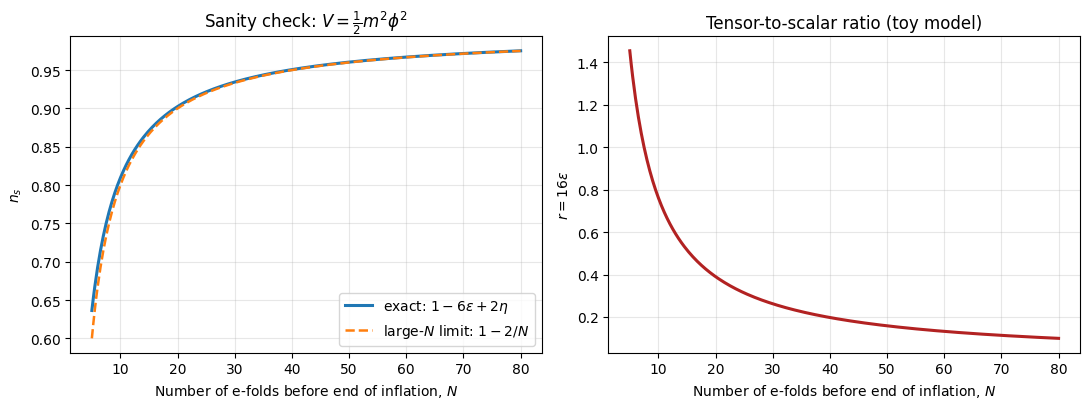

wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig2_tree_level_valley.png


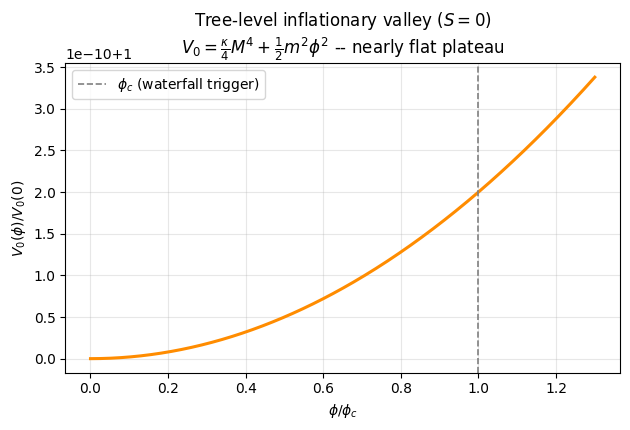

wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig3_tree_level_blue_tilt.png


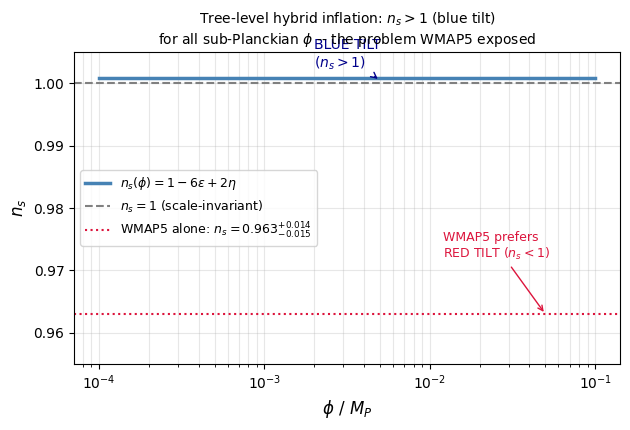

wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig4_hilltop_formation.png


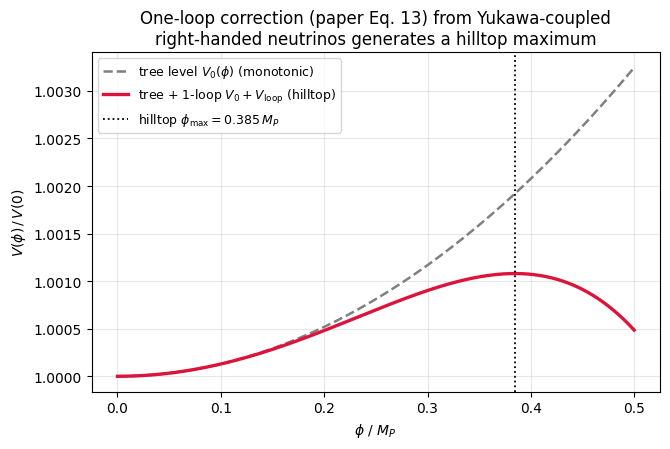

wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig5_ns_and_N_profile.png


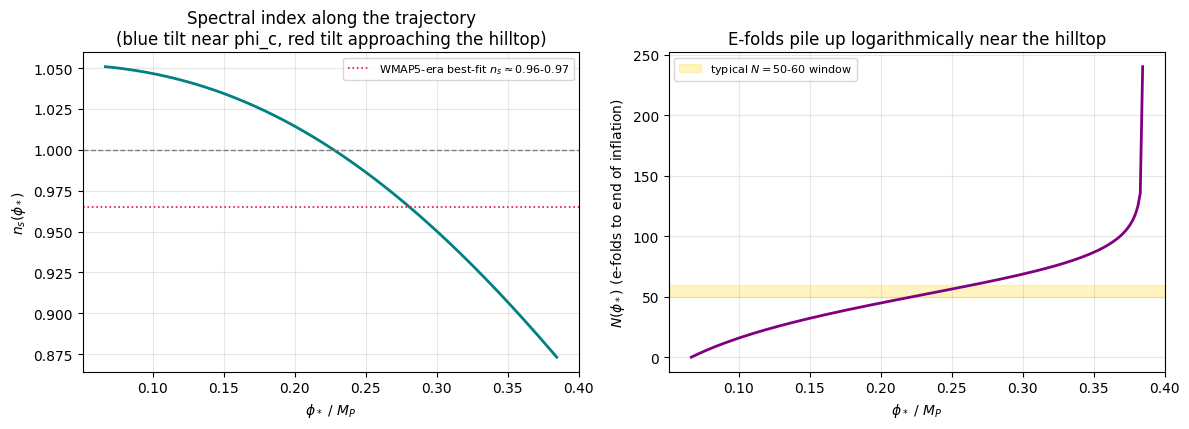

wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig6_ns_r_scan.png


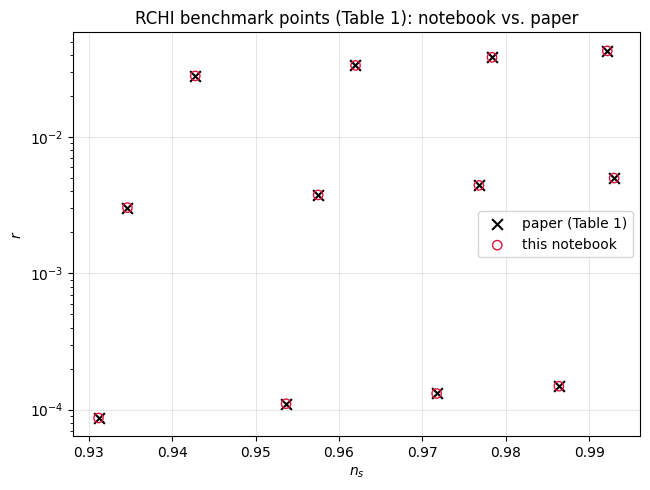

wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig7_ns_vs_phistar_subplanckian.png


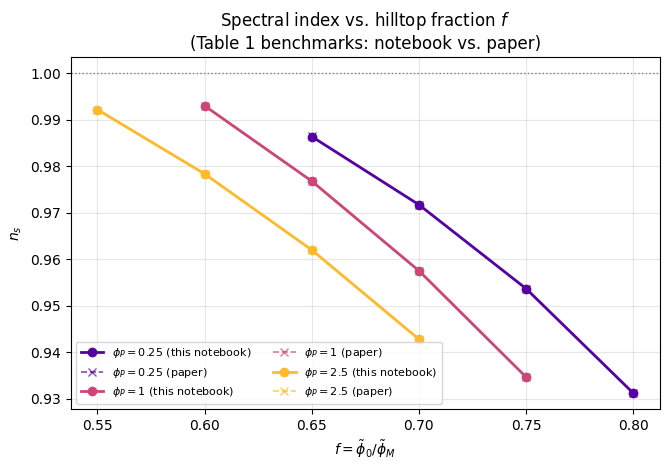

All figures generated successfully!


In [11]:
"""
Generates every figure for the notebook. All functions are already defined
in the previous cells, so no import is needed.
Figures are written to ./figures/.
"""
 
import numpy as np
# [#fixed: removed matplotlib.use("Agg"); it forced a non-interactive backend so no figure was ever displayed inline in Jupyter/Colab]
import matplotlib.pyplot as plt
from scipy.optimize import brentq
 
import os
FIGDIR = os.path.join(os.getcwd(), "figures")
os.makedirs(FIGDIR, exist_ok=True)
 
# Note: All functions (epsilon_toy, ns_toy, r_toy, V_tree, critical_field, 
# make_V_and_dV, find_hilltop, V_total, epsilon, eta, ns_from_eps_eta, 
# r_from_eps, N_efolds, module5_observables, etc.) are already defined 
# in the previous code cells!
 
def savefig(fig, name):
    path = os.path.join(FIGDIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("wrote", path)
    # [#fixed: figures are displayed inline (plt.show) as well as saved]
    plt.show()
    plt.close(fig)
 
 
#Figure 1 (Module 1): toy chaotic-inflation sanity check
def fig1_toy_check():
    phi_end = np.sqrt(2.0)
    N = np.linspace(5, 80, 300)
    ns_exact = np.array([ns_toy(n, phi_end) for n in N])
    ns_approx = 1.0 - 2.0 / N
    r_exact = np.array([r_toy(n, phi_end) for n in N])
 
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    ax = axes[0]
    ax.plot(N, ns_exact, label=r"exact: $1-6\epsilon+2\eta$", lw=2.2)
    ax.plot(N, ns_approx, "--", label=r"large-$N$ limit: $1-2/N$", lw=1.8)
    ax.set_xlabel("Number of e-folds before end of inflation, $N$")
    ax.set_ylabel(r"$n_s$")
    ax.set_title(r"Sanity check: $V=\frac{1}{2}m^2\phi^2$")
    ax.legend()
    ax.grid(alpha=0.3)
 
    ax = axes[1]
    ax.plot(N, r_exact, color="firebrick", lw=2.2)
    ax.set_xlabel("Number of e-folds before end of inflation, $N$")
    ax.set_ylabel(r"$r=16\epsilon$")
    ax.set_title("Tensor-to-scalar ratio (toy model)")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    savefig(fig, "fig1_toy_sanity_check.png")
 
 
#Figure 2 (Module 2): tree-level valley potential V0(phi) = S=0 slice
def fig2_tree_potential(kappa=1.0, M=1e-3, m=1e-8):
    phi_c = critical_field(kappa, M, g=1.0)
    if phi_c == 0:
        return
    phis = np.linspace(0, 1.3 * phi_c, 400)
    V0 = V_tree(phis, kappa, M, m)
    if V0[0] == 0:
        return
 
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    ax.plot(phis / phi_c, V0 / V0[0], lw=2.2, color="darkorange")
    ax.axvline(1.0, color="gray", ls="--", lw=1.2,
               label=r"$\phi_c$ (waterfall trigger)")
    ax.set_xlabel(r"$\phi / \phi_c$")
    ax.set_ylabel(r"$V_0(\phi) / V_0(0)$")
    ax.set_title("Tree-level inflationary valley ($S=0$)\n"
                  r"$V_0=\frac{\kappa}{4}M^4+\frac{1}{2}m^2\phi^2$ -- nearly flat plateau")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    savefig(fig, "fig2_tree_level_valley.png")
 
#Figure 3 (Module 3): Tree-level blue tilt problem
def fig3_tree_level_blue_tilt(kappa=1.0, M=1e-2, m=1e-6):
    """Show ns(phi) on V_tree ALONE (no loop correction): this stays
    above 1 for all sub-Planckian phi, illustrating the blue tilt problem."""
 
    def Vfun(phi):
        return V_tree(phi, kappa, M, m)
 
    def dVfun(phi):
        return dV_tree(phi, m)
 
    # Use a log-spaced grid to better resolve the behavior
    phis = np.logspace(-4, -1, 400)  # from 1e-4 to 1e-1
 
    # Compute slow-roll parameters EXACTLY
    eps = np.zeros_like(phis)
    eta_val = np.zeros_like(phis)
    ns = np.zeros_like(phis)
 
    for i, phi in enumerate(phis):
        V = Vfun(phi)
        dV = dVfun(phi)
        d2V = m**2  # For tree-level, V'' = m²
 
        eps[i] = 0.5 * (dV / V)**2  # Mp=1
        eta_val[i] = d2V / V        # Mp=1
        ns[i] = 1.0 - 6.0 * eps[i] + 2.0 * eta_val[i]
 
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
 
    # Plot ns(phi)
    ax.semilogx(phis, ns, lw=2.5, color="steelblue", 
                label=r"$n_s(\phi) = 1 - 6\epsilon + 2\eta$")
 
    # Reference lines
    ax.axhline(1.0, color="gray", ls="--", lw=1.5, label=r"$n_s = 1$ (scale-invariant)")
    ax.axhline(0.963, color="crimson", ls=":", lw=1.5, 
               label=r"WMAP5 alone: $n_s = 0.963^{+0.014}_{-0.015}$")  # [#fixed: quoted WMAP5 value corrected (was 0.963 +/- 0.012)]
 
    # Set y-axis limits to clearly show the blue tilt
    # [#fixed: lower y-limit 0.98 -> 0.955; the WMAP5 line at 0.963 and its annotation were outside the axes and invisible]
    ax.set_ylim(0.955, 1.005)
 
    ax.set_xlabel(r"$\phi\ / \ M_P$", fontsize=12)
    ax.set_ylabel(r"$n_s$", fontsize=12)
    ax.set_title("Tree-level hybrid inflation: $n_s > 1$ (blue tilt)\n"
                 r"for all sub-Planckian $\phi$ -- the problem WMAP5 exposed", 
                 fontsize=10)
    ax.legend(loc='best', fontsize=9)
    ax.grid(alpha=0.3, which='both')
 
    # Add annotation showing the problem
    ax.annotate("BLUE TILT\n($n_s > 1$)", 
                xy=(0.005, 1.0004), 
                xytext=(0.002, 1.0025),
                fontsize=10, color='darkblue',
                arrowprops=dict(arrowstyle='->', color='darkblue', lw=1))
 
    ax.annotate("WMAP5 prefers\nRED TILT ($n_s < 1$)", 
                xy=(0.05, 0.963), 
                xytext=(0.012, 0.972),
                fontsize=9, color='crimson',
                arrowprops=dict(arrowstyle='->', color='crimson', lw=1))
 
    fig.tight_layout()
    savefig(fig, "fig3_tree_level_blue_tilt.png")
    return phis, ns
 
#Figure 4 (Module 4): loop correction creates a hilltop maximum
# defaults = Table 1 benchmark (f=0.65, phi_P=0.25), matching Module 4/5/6
def fig4_hilltop(kappa=4.0, M=1.517864e-3, m=3.712526e-7, y=2.070586e-3, g=None):
    # [#fixed: g defaults to sqrt(y) exactly instead of the literal 0.0454922]
    if g is None:
        g = np.sqrt(y)
    phi_c = critical_field(kappa, M, g)
    Vfun, dVfun, d2Vfun = make_V_and_dV(kappa, M, m, y, phi_c)
    phi_max = find_hilltop(Vfun, dVfun, 1e-4, 0.9)
    if phi_max is None:
        return
    phis = np.linspace(1e-5, 1.3 * phi_max, 600)
    Vtree = V_tree(phis, kappa, M, m)
    Vtot = V_total(phis, kappa, M, m, y, phi_c)
 
    fig, ax = plt.subplots(figsize=(6.8, 4.6))
    V0 = V_tree(np.array([0.0]), kappa, M, m)[0]
    if V0 == 0:
        return
    ax.plot(phis, Vtree / V0, "--", lw=1.8, color="gray",
            label=r"tree level $V_0(\phi)$ (monotonic)")
    ax.plot(phis, Vtot / V0, lw=2.4, color="crimson",
            label=r"tree + 1-loop $V_0+V_{\rm loop}$ (hilltop)")
    ax.axvline(phi_max, color="black", ls=":", lw=1.3,
               label=rf"hilltop $\phi_{{\rm max}}={phi_max:.3f}\,M_P$")
    ax.set_xlabel(r"$\phi\ / \ M_P$")
    ax.set_ylabel(r"$V(\phi)\, / \, V(0)$")
    ax.set_title("One-loop correction (paper Eq. 13) from Yukawa-coupled\n"
                  r"right-handed neutrinos generates a hilltop maximum")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    savefig(fig, "fig4_hilltop_formation.png")
    return phi_max
 
 
#Figure 5 (Module 5): ns(phi) and N(phi) along the inflaton trajectory
# defaults = Table 1 benchmark (f=0.65, phi_P=0.25), matching Module 4/5/6
def fig5_ns_profile(kappa=4.0, M=1.517864e-3, m=3.712526e-7, y=2.070586e-3, g=None):
    # [#fixed: g defaults to sqrt(y) exactly; ns along the trajectory uses the NLO expression]
    if g is None:
        g = np.sqrt(y)
    phi_c = critical_field(kappa, M, g)
    Vfun, dVfun, d2Vfun = make_V_and_dV(kappa, M, m, y, phi_c)
    d3Vfun = make_d3V(y, phi_c)
    phi_max = find_hilltop(Vfun, dVfun, 1e-4, 0.9)
    if phi_max is None:
        return
    if phi_c >= phi_max:
        return
 
    phis = np.geomspace(phi_c * 1.0005, phi_max * 0.999995, 400)
    Ns, nss, rs = [], [], []
    for p in phis:
        N = N_efolds(p, phi_c, Vfun, dVfun)
        eps = epsilon(p, Vfun, dVfun)
        eta_val = eta(p, Vfun, dVfun, d2Vfun)
        Ns.append(N)
        nss.append(ns_nlo(eps, eta_val, xi2(p, Vfun, dVfun, d3Vfun)))
        rs.append(r_nlo(eps, eta_val))
    Ns, nss, rs = map(np.array, (Ns, nss, rs))
 
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    ax = axes[0]
    ax.plot(phis, nss, lw=2.0, color="teal")
    ax.axhline(1.0, color="gray", ls="--", lw=1)
    ax.axhline(0.965, color="crimson", ls=":", lw=1.2,
               label=r"WMAP5-era best-fit $n_s\approx0.96$-$0.97$")
    ax.set_xlabel(r"$\phi_*\ / \ M_P$")
    ax.set_ylabel(r"$n_s(\phi_*)$")
    ax.set_title("Spectral index along the trajectory\n"
                  "(blue tilt near phi_c, red tilt approaching the hilltop)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
 
    ax = axes[1]
    ax.plot(phis, Ns, lw=2.0, color="purple")
    ax.axhspan(50, 60, color="gold", alpha=0.25, label="typical $N=50$-$60$ window")
    ax.set_xlabel(r"$\phi_*\ / \ M_P$")
    ax.set_ylabel(r"$N(\phi_*)$ (e-folds to end of inflation)")
    ax.set_title("E-folds pile up logarithmically near the hilltop")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    savefig(fig, "fig5_ns_and_N_profile.png")
    return phis, nss, Ns
 
 
#Figure 6 (Module 6): ns-r scatter over the paper's ACTUAL Table 1
# benchmark grid, plotted against the paper's own reported points.
def fig6_ns_r_scan():
    results = module6_validate_table1(verbose=False)
    ns_ours = [r["ns_ours"] for r in results]
    r_ours  = [r["r_ours"]  for r in results]
    ns_pap  = [r["ns_paper"] for r in results]
    r_pap   = [r["r_paper"]  for r in results]

    fig, ax = plt.subplots(figsize=(6.6, 5.0))
    ax.scatter(ns_pap, r_pap, marker="x", s=60, color="black", label="paper (Table 1)")
    ax.scatter(ns_ours, r_ours, marker="o", s=45, color="crimson",
               facecolors="none", label="this notebook")
    ax.set_xlabel(r"$n_s$")
    ax.set_ylabel(r"$r$")
    ax.set_yscale("log")
    ax.set_title("RCHI benchmark points (Table 1): notebook vs. paper")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    savefig(fig, "fig6_ns_r_scan.png")
    return results
 
#Figure 7 (Module 6): ns vs f for each phi_P group in Table 1 --
# the paper's own scan variable (compare to their Fig. 5, log10(A) & ns vs f),
# rather than an invented y-grid with no connection to a real solution.
def fig7_ns_vs_phistar():
    results = module6_validate_table1(verbose=False)

    # group by phi_P (0.25, 1.00, 2.50)
    phi_Ps = sorted(set(r["phi_P"] for r in results))
    colors = plt.cm.plasma(np.linspace(0.15, 0.85, len(phi_Ps)))

    fig, ax = plt.subplots(figsize=(6.8, 4.8))
    for phi_P, c in zip(phi_Ps, colors):
        group = [r for r in results if r["phi_P"] == phi_P]
        group.sort(key=lambda r: r["f"])
        fs = [g["f"] for g in group]
        ns_ours = [g["ns_ours"] for g in group]
        ns_pap = [g["ns_paper"] for g in group]
        ax.plot(fs, ns_ours, "-o", color=c, lw=2.0,
                 label=rf"$\phi_P={phi_P:g}$ (this notebook)")
        ax.plot(fs, ns_pap, "--x", color=c, lw=1.2, alpha=0.7,
                 label=rf"$\phi_P={phi_P:g}$ (paper)")

    ax.axhline(1.0, color="gray", ls=":", lw=1)
    ax.set_xlabel(r"$f = \tilde\phi_0/\tilde\phi_M$")
    ax.set_ylabel(r"$n_s$")
    ax.set_title("Spectral index vs. hilltop fraction $f$\n"
                  "(Table 1 benchmarks: notebook vs. paper)")
    ax.legend(fontsize=8, ncol=2)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    savefig(fig, "fig7_ns_vs_phistar_subplanckian.png")
    return results
 
 
# Run all figure generators
if __name__ == "__main__":
    print("Generating figures...")
    fig1_toy_check()
    fig2_tree_potential()
    fig3_tree_level_blue_tilt()
    fig4_hilltop()
    fig5_ns_profile()
    fig6_ns_r_scan()
    fig7_ns_vs_phistar()
    print("All figures generated successfully!")
 

## Part 2: Reproducing the Paper's Own Published Figures

Everything above (Modules 1-9, Table 1 validation) checked the underlying
**physics** against the paper's numbers. This section reproduces the paper's
**actual published figures** (Figs. 1, 3, 4, 5, 6), using:

- **Figs. 1, 3, 4**: the paper's exact closed-form equations for TLHI
  (Eqs. 2-9) and RCHI (Eqs. 14-24) -- these are analytic, so no numerical
  hilltop-hunting is needed, and there is no approximation involved beyond
  what the paper itself makes (treating $\tilde A_\phi$ as
  $\phi$-independent, and using $\kappa\sim\lambda\sim10^{-3}$ as stated
  in the text after Eq. 5).
- **Figs. 5, 6**: the paper's full numerical scan (Module 9): fix $f$, scan
  $V_0$ until $N_0$ matches the thermal-reheat relation Eq. 25, then solve
  $A$ from the WMAP5 curvature-perturbation constraint, with the full
  $\phi$-dependence of $A_\phi$ and next-to-leading-order $n_s$, $r$, $\Delta_{\mathcal R}$.
  The scan covers the paper's whole range $0.4 \le f \le 0.9$.
  [#fixed: Figs. 5 and 6 are computed by the scan instead of being spline-interpolated through Table 1, which only covered $f\approx0.55$-$0.80$]
- **WMAP5+BAO+SN contours**: hand-traced by eye from the paper's own
  Fig. 1/Fig. 6 (pixel positions, not the original numerical likelihood
  surface -- that would require the actual WMAP5 MCMC chains). Good enough
  to see where curves fall relative to the bounds; not survey-grade.


In [12]:
# [#fixed: DeltaR is defined once in the first code cell; the duplicate definition here was removed]
#MODULE 8: exact closed-form TLHI/RCHI equations from the paper (Eqs. 2-24)
# These are used to reproduce the paper's own Figures 1-4 exactly as
# published -- no numerical hilltop-hunting needed, since the paper itself
# works with these closed forms (only Table 1 / Figs. 5-6 need the full
# numerical treatment with NLO corrections, which Module 9 carries out) [#fixed: module reference corrected].

kappa_ref = 1e-3
lam_ref = 1e-3   # paper: "with kappa ~ lambda ~ 1e-3" (text after Eq. 5)

# ---- TLHI: tree-level hybrid inflation (Eqs. 2-9) ----
def eps_TLHI(phit, eta0):
    return eta0 * phit**2 / (phit**2 + 1)**2

def eta_TLHI(phit, eta0):
    return eta0 / (phit**2 + 1)

def ns_TLHI(phit0, eta0):
    """Eq. 8."""
    return 1 - 4*eta0*(phit0**2 - 0.5)/(phit0**2 + 1)**2

def r_TLHI(phit0, eta0):
    """Eq. 9."""
    return 16*eta0*phit0**2/(phit0**2 + 1)**2

def eta0_of_V0_TLHI(phit0, V0):
    """Eq. 7."""
    return (1 + phit0**2)**3 / (24*np.pi**2*DeltaR**2*phit0**2) * V0

def V0_of_eta0_TLHI(phit0, eta0):
    """Eq. 7, inverted."""
    return eta0 * 24*np.pi**2*DeltaR**2*phit0**2 / (1 + phit0**2)**3

def phitc_TLHI(V0, eta0, kappa=kappa_ref, lam=lam_ref):
    """phi_c = sqrt(2 kappa/lam^2) V0^(1/4); phi~c = sqrt(eta0/2)(phi_c/mP)."""
    phi_c = np.sqrt(2*kappa/lam**2) * V0**0.25
    return np.sqrt(eta0/2.0) * phi_c

def N0_TLHI(phit0, phitc, eta0):
    """Eq. 5."""
    return 1.0/(2*eta0) * (phit0**2 - phitc**2 + np.log(phit0**2/phitc**2))

def solve_eta0_for_N0_TLHI(phit0, N_target, kappa=kappa_ref, lam=lam_ref,
                            eta0_lo=1e-8, eta0_hi=5.0, n=6000):
    """Scan eta0 (equivalently V0) at fixed phi~0 for the N0=N_target point
    used to place the dots on Fig. 1."""
    def f(eta0):
        V0 = V0_of_eta0_TLHI(phit0, eta0)
        phitc = phitc_TLHI(V0, eta0, kappa, lam)
        if not (0 < phitc < phit0):
            return np.nan
        return N0_TLHI(phit0, phitc, eta0) - N_target
    grid = np.geomspace(eta0_lo, eta0_hi, n)
    vals = np.array([f(e) for e in grid])
    ok = ~np.isnan(vals)
    if ok.sum() < 2:
        return None
    gg, vv = grid[ok], vals[ok]
    idx = np.where(np.diff(np.sign(vv)) != 0)[0]
    if len(idx) == 0:
        return None
    i = idx[0]
    return brentq(f, gg[i], gg[i+1], xtol=1e-16)


# ---- RCHI: radiatively-corrected hybrid inflation (Eqs. 14-24) ----
# (Aphi-tilde is treated as phi-independent, per the paper's own leading
# order simplification right before Eq. 15 -- exact same approximation
# the paper uses for Figs. 1, 3, and 4.)
def ns_RCHI(phit0, eta0, Atilde):
    """Eq. 22."""
    num = 1 - 2*(1+3*Atilde)*phit0**2 + 5*Atilde*phit0**4 - 6*Atilde**2*phit0**6
    den = (1 + phit0**2 - Atilde*phit0**4)**2
    return 1 + 2*eta0*num/den

def r_RCHI(phit0, eta0, Atilde):
    """Eq. 23."""
    num = 16*eta0*(phit0 - 2*Atilde*phit0**3)**2
    den = (1 + phit0**2 - Atilde*phit0**4)**2
    return num/den

def V0_of_eta0_RCHI(phit0, Atilde, eta0):
    """Eq. 16, inverted."""
    num = 24*np.pi**2*DeltaR**2*phit0**2*(1 - 2*Atilde*phit0**2)**2
    den = (1 + phit0**2 - Atilde*phit0**4)**3
    return eta0*num/den

def N0_RCHI(phit0, phitc, Atilde, eta0):
    """Eq. 17."""
    term1 = (phit0**2 - phitc**2)/2 + np.log(phit0**2/phitc**2)
    term2 = (1+4*Atilde)*np.log((1-2*Atilde*phit0**2)/(1-2*Atilde*phitc**2))/(4*Atilde)
    return (term1 - term2)/(2*eta0)

def phitM_of_Atilde(Atilde):
    """phi~_M = 1/sqrt(2 Atilde), the field value at the loop-induced maximum."""
    return 1.0/np.sqrt(2*Atilde)

def solve_eta0_for_N0_RCHI(phit0, Atilde, N_target, kappa=kappa_ref, lam=lam_ref,
                            eta0_lo=1e-8, eta0_hi=200.0, n=6000):
    def f(eta0):
        V0 = V0_of_eta0_RCHI(phit0, Atilde, eta0)
        phi_c = np.sqrt(2*kappa/lam**2)*V0**0.25
        phitc = np.sqrt(eta0/2.0)*phi_c
        if not (0 < phitc < phit0):
            return np.nan
        return N0_RCHI(phit0, phitc, Atilde, eta0) - N_target
    grid = np.geomspace(eta0_lo, eta0_hi, n)
    vals = np.array([f(e) for e in grid])
    ok = ~np.isnan(vals)
    if ok.sum() < 2:
        return None
    gg, vv = grid[ok], vals[ok]
    idx = np.where(np.diff(np.sign(vv)) != 0)[0]
    if len(idx) == 0:
        return None
    i = idx[0]
    return brentq(f, gg[i], gg[i+1], xtol=1e-16)


In [13]:
#Reproducing the paper's own Figures 1, 3 and 4 (r vs ns), plus an
# approximate WMAP5+BAO+SN contour hand-traced from the paper's Fig. 1.
#
# IMPORTANT CAVEAT: the shaded contours below are a VISUAL APPROXIMATION of
# the WMAP5+BAO+SN 68%/95% region, traced by eye from the paper's own
# Fig. 1. They are NOT the original numerical likelihood surface (that
# would require the actual WMAP5 MCMC chains). The curves and dots, in
# contrast, are computed exactly from the paper's closed-form equations
# (Module 8) and are not approximations.

from matplotlib.patches import Polygon

CONTOUR_95 = np.array([
    [0.925,0.000],[0.935,0.02],[0.945,0.06],[0.953,0.11],[0.962,0.16],
    [0.972,0.21],[0.982,0.245],[0.990,0.25],[0.997,0.22],[1.001,0.15],
    [1.002,0.08],[1.000,0.03],[0.996,0.000],[0.925,0.000]
])
CONTOUR_68 = np.array([
    [0.943,0.000],[0.951,0.03],[0.959,0.07],[0.967,0.11],[0.975,0.145],
    [0.983,0.155],[0.990,0.13],[0.995,0.09],[0.996,0.04],[0.993,0.000],
    [0.943,0.000]
])

def add_wmap_contours(ax, logy=False):
    c95, c68 = CONTOUR_95.copy(), CONTOUR_68.copy()
    if logy:
        eps = 1e-5
        c95[:,1] = np.log10(np.maximum(c95[:,1], eps))
        c68[:,1] = np.log10(np.maximum(c68[:,1], eps))
    ax.add_patch(Polygon(c95, closed=True, facecolor="#f4a582", edgecolor="none", alpha=0.9, zorder=0))
    ax.add_patch(Polygon(c68, closed=True, facecolor="#d6604d", edgecolor="none", alpha=0.9, zorder=1))


def fig8_paper_fig1():
    """Reproduces paper Fig. 1: r vs ns for TLHI."""
    fig, ax = plt.subplots(figsize=(6.4, 5.0))
    add_wmap_contours(ax)
    # [#fixed: eta0 grid extended from 0.5 to 20; with the short grid the phi~0>>1 line ended at ns=0.97 while its N0=50/60 dots (which need eta0 ~ 0.6-0.7) lay far off the line]
    eta0_grid = np.geomspace(1e-4, 20.0, 4000)
    for phit0, color, label in [(1.0, "tab:blue", r"$\tilde\phi_0=1$"),
                                  (8.0, "tab:green", r"$\tilde\phi_0\gg1$")]:
        ns, r = ns_TLHI(phit0, eta0_grid), r_TLHI(phit0, eta0_grid)
        m = (r < 0.42) & (ns > 0.92)
        ax.plot(ns[m], r[m], color=color, lw=1.6)
        for Nt, ms in [(50, 5), (60, 8)]:
            e = solve_eta0_for_N0_TLHI(phit0, Nt)
            if e:
                ax.plot(ns_TLHI(phit0, e), r_TLHI(phit0, e), "o", color=color, ms=ms)
        # [#fixed: labels placed on the line at r~0.30 instead of at the ns=1 end, where they overlapped each other]
        j = np.argmin(np.abs(r[m] - 0.30))
        ax.text(ns[m][j] + 0.003, r[m][j] + 0.004, label, color=color, fontsize=9)
    phit0 = 0.67
    ns, r = ns_TLHI(phit0, eta0_grid), r_TLHI(phit0, eta0_grid)
    m = (r < 0.42) & (ns < 1.02) & (ns > 0.99)
    ax.plot(ns[m], r[m], color="black", lw=1.2)
    for Nt, ms in [(50, 5), (60, 8)]:
        e = solve_eta0_for_N0_TLHI(phit0, Nt)
        if e:
            ax.plot(ns_TLHI(phit0, e), r_TLHI(phit0, e), "o", color="black", ms=ms)
    ax.text(1.009, 0.24, "Flat Potential\n" + r"$\tilde\phi_0<0.67$", fontsize=8)
    ax.text(0.928, 0.20, "Not Allowed", fontsize=9)
    ax.set_xlim(0.92, 1.02); ax.set_ylim(0, 0.4)
    ax.set_xlabel(r"$n_s$"); ax.set_ylabel(r"$r$")
    ax.set_title("Fig. 1: TLHI, r vs $n_s$ (paper reproduction)")
    fig.tight_layout()
    savefig(fig, "fig8_paper_fig1.png")


def fig9_paper_fig3():
    """Reproduces paper Fig. 3: r vs ns for RCHI, f=0.4 and f=0.65."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    eta0_grid = np.geomspace(1e-5, 2.0, 500)
    for ax, f in zip(axes, (0.4, 0.65)):
        add_wmap_contours(ax)
        # [#fixed: flat-potential line uses phi~0 = 0.54 (was 0.6); with 0.6 the f=0.4 line tilted to ns<1, whereas the paper and the label give ns>1 with dots at (1.003, 0.10)]
        for label, phit0_val, color in [(r"$\tilde\phi_0=1$", 1.0, "tab:blue"),
                                          (r"$\tilde\phi_0\gg1$", 8.0, "tab:green"),
                                          (r"$\tilde\phi_0<0.54$", 0.54, "black")]:
            Atilde = f**2/(2*phit0_val**2)
            ns, r = ns_RCHI(phit0_val, eta0_grid, Atilde), r_RCHI(phit0_val, eta0_grid, Atilde)
            m = (r > 0) & (r < 0.42) & np.isfinite(ns) & np.isfinite(r)
            ax.plot(ns[m], r[m], color=color, lw=1.4)
            for Nt, ms in [(50, 5), (60, 8)]:
                e = solve_eta0_for_N0_RCHI(phit0_val, Atilde, Nt)
                if e:
                    nsv, rv = ns_RCHI(phit0_val, e, Atilde), r_RCHI(phit0_val, e, Atilde)
                    if 0 < rv < 0.42:
                        ax.plot(nsv, rv, "o", color=color, ms=ms)
        ax.set_xlim(0.92, 1.02); ax.set_ylim(0, 0.4)
        ax.set_xlabel(r"$n_s$"); ax.set_title(f"f = {f}")
    axes[0].set_ylabel(r"$r$")
    fig.suptitle("Fig. 3: RCHI, r vs $n_s$ (paper reproduction)")
    fig.tight_layout()
    savefig(fig, "fig9_paper_fig3.png")


def fig10_paper_fig4():
    """Reproduces paper Fig. 4: r vs ns for RCHI at fixed phi~_M."""
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
    fs = [0.4, 0.5, 1/np.sqrt(3), 0.7, 0.8]
    eta0_grid = np.geomspace(1e-8, 200.0, 4000)
    for ax, phitM in zip(axes, (100.0, 1.0, 0.1)):
        add_wmap_contours(ax)
        Atilde = 1.0/(2*phitM**2)
        for f in fs:
            phit0 = f*phitM
            ns, r = ns_RCHI(phit0, eta0_grid, Atilde), r_RCHI(phit0, eta0_grid, Atilde)
            m = (r > 0) & (r < 0.27) & np.isfinite(ns) & np.isfinite(r)
            ax.plot(ns[m], r[m], color="black", lw=1.0)
            for Nt, ms in [(50, 4), (60, 7)]:
                e = solve_eta0_for_N0_RCHI(phit0, Atilde, Nt, eta0_hi=200.0)
                if e:
                    nsv, rv = ns_RCHI(phit0, e, Atilde), r_RCHI(phit0, e, Atilde)
                    if 0 <= rv < 0.27:
                        ax.plot(nsv, rv, "o", color="black", ms=ms)
        ax.set_xlim(0.90, 1.04); ax.set_ylim(0, 0.26)
        ax.set_xlabel(r"$n_s$"); ax.set_title(rf"$\tilde\phi_M={phitM:g}$")
    axes[0].set_ylabel(r"$r$")
    fig.suptitle("Fig. 4: RCHI, r vs $n_s$ at fixed $\\tilde\\phi_M$ (paper reproduction)")
    fig.tight_layout()
    savefig(fig, "fig10_paper_fig4.png")


In [14]:
#Reproducing the paper's Figures 5 and 6 from the full numerical scan
# (Module 9): fix phi_P and f, solve V0 and A, read off ns and r.
# [#fixed: replaces the cubic-spline interpolation through Table 1 (valid only for f ~ 0.55-0.80) with the paper's own scan over 0.4 <= f <= 0.9]

_SCAN_CACHE = {}
FS_SCAN = np.round(np.arange(0.40, 0.9001, 0.01), 2)

def get_scan(phi_P):
    if phi_P not in _SCAN_CACHE:
        _SCAN_CACHE[phi_P] = scan_rchi(phi_P, FS_SCAN)
    return _SCAN_CACHE[phi_P]


SCAN_COLORS = {0.25: "tab:green", 1.00: "tab:blue", 2.50: "tab:brown"}


def fig11_paper_fig5():
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    for phiP, color in SCAN_COLORS.items():
        res = get_scan(phiP)
        f = np.array([s["f"] for s in res]); logA = np.array([s["log10A"] for s in res])
        ns = np.array([s["ns"] for s in res])
        axes[0].plot(f, logA, color=color, lw=2, label=rf"$\phi_P={phiP:g}$")
        axes[1].plot(ns, logA, color=color, lw=2, label=rf"$\phi_P={phiP:g}$")
    axes[0].set_xlim(0.4, 0.9); axes[0].set_ylim(-13.5, -12.55)
    axes[1].set_xlim(0.82, 1.03); axes[1].set_ylim(-13.5, -12.55)
    axes[0].set_xlabel("f"); axes[0].set_ylabel(r"$\log_{10}A$"); axes[0].legend(fontsize=8)
    axes[1].set_xlabel(r"$n_s$")
    fig.suptitle("Fig. 5 (paper): $\\log_{10}A$ vs $f$ and $n_s$ -- full scan")
    fig.tight_layout()
    savefig(fig, "fig11_paper_fig5.png")


def fig12_paper_fig6():
    fig, ax = plt.subplots(figsize=(6.6, 5.2))
    add_wmap_contours(ax, logy=True)
    for phiP, color in SCAN_COLORS.items():
        res = get_scan(phiP)
        f = np.array([s["f"] for s in res]); ns = np.array([s["ns"] for s in res])
        lr = np.log10(np.array([s["r"] for s in res]))
        ax.plot(ns, lr, color=color, lw=2, label=rf"$\phi_P={phiP:g}$", zorder=3)
        on_grid = np.isclose((f * 20) % 1, 0) | np.isclose((f * 20) % 1, 1)
        ax.plot(ns[on_grid], lr[on_grid], "o", color="black", ms=3, zorder=4)   # f in steps of 0.05
        fi = find_inflection_f(phiP)
        si = solve_rchi_point(phiP, fi, guess=(res[len(res) // 2]["V0"], res[len(res) // 2]["A"]))
        ax.plot(si["ns"], np.log10(si["r"]), "o", color=color, ms=8, zorder=5,
                markeredgecolor="black")                                          # inflection point f_i
    ax.set_xlim(0.915, 1.015); ax.set_ylim(-5, -0.5)
    ax.set_xlabel(r"$n_s$"); ax.set_ylabel(r"$\log_{10}r$")
    ax.legend(fontsize=9, loc="lower left")
    fig.suptitle("Fig. 6 (paper): $\\log_{10}r$ vs $n_s$ -- full scan, f = 0.4-0.9")
    fig.tight_layout()
    savefig(fig, "fig12_paper_fig6.png")


wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig8_paper_fig1.png


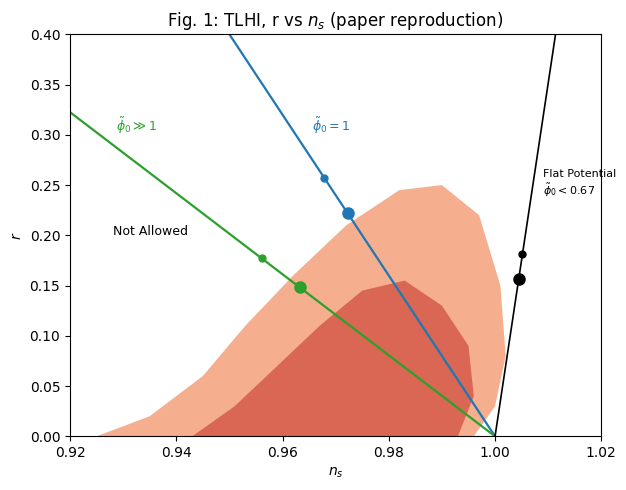

wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig9_paper_fig3.png


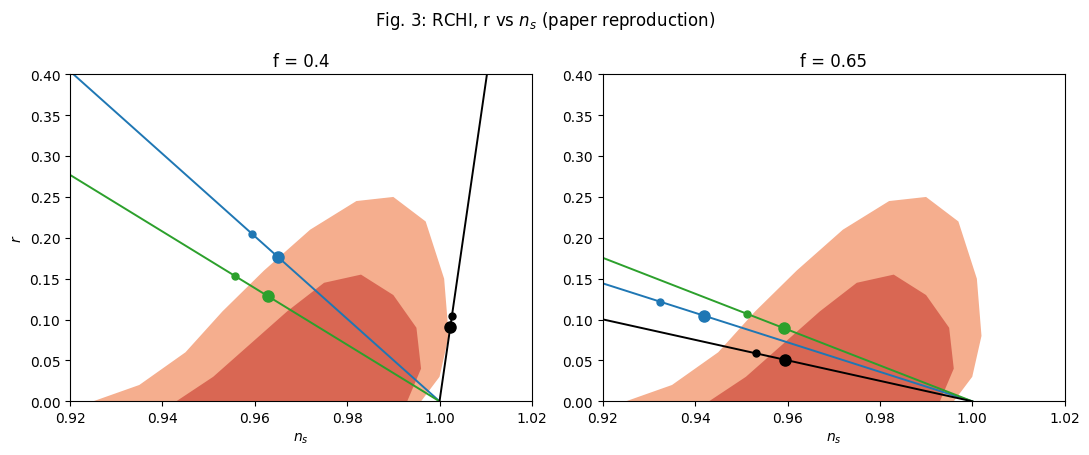

wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig10_paper_fig4.png


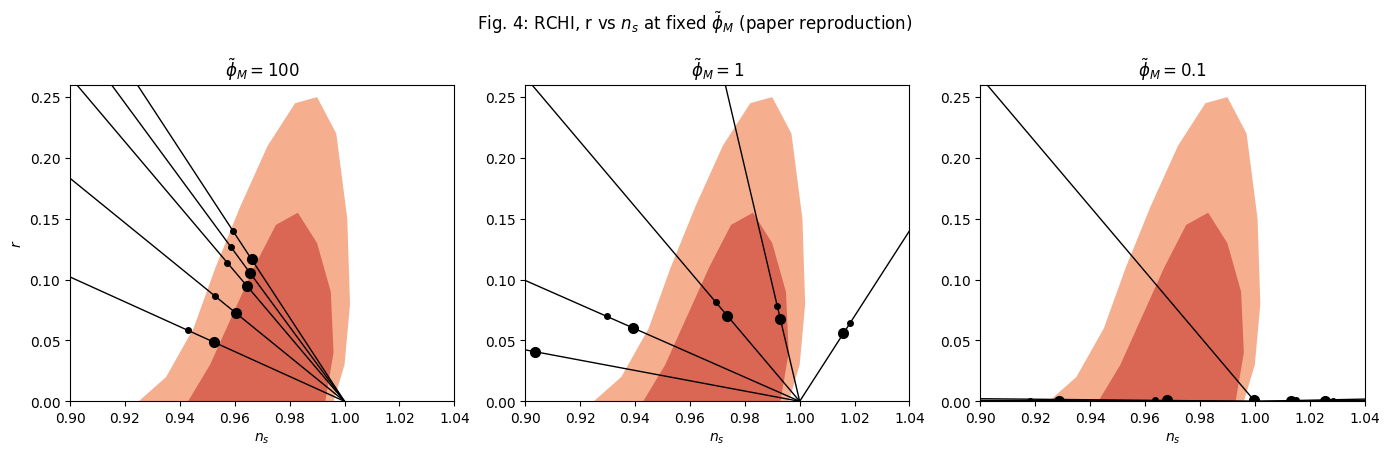

wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig11_paper_fig5.png


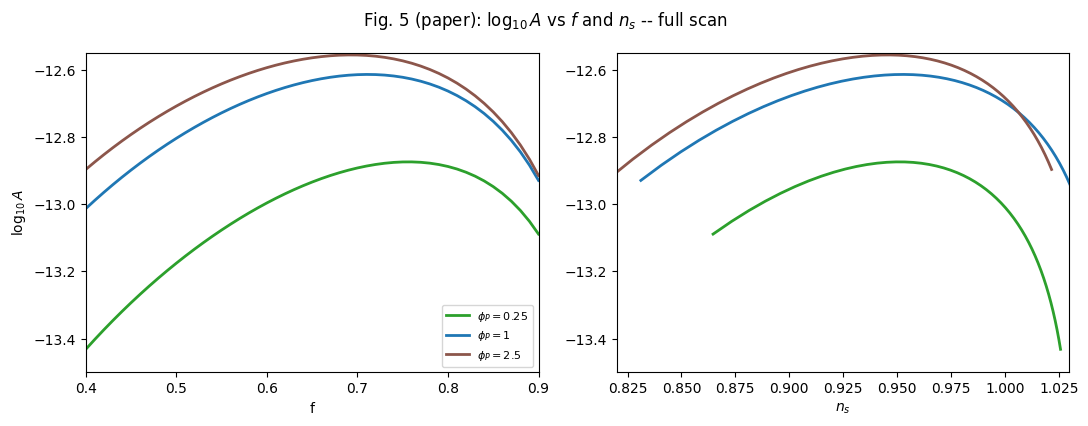

wrote d:\M-C-S\my files (pallasarchive)\nust and study files\Study Projects\SUSY Research\Project SUSY\Reproducing [Hybrid Inflation Revisited in Light of WMAP5]\figures\fig12_paper_fig6.png


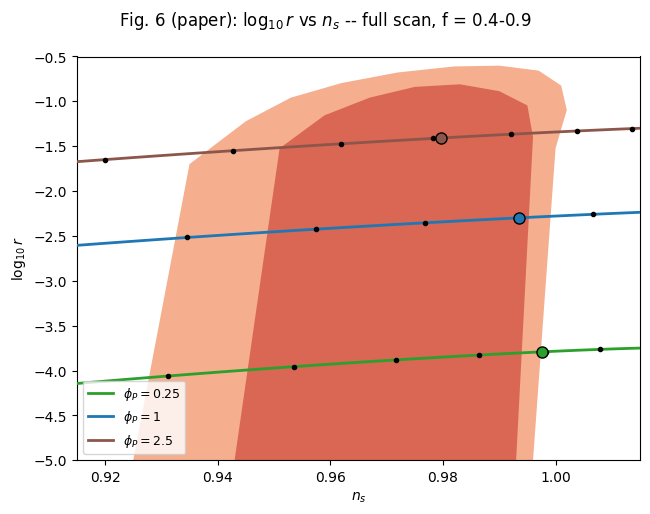

In [15]:
if __name__ == "__main__":
    fig8_paper_fig1()
    fig9_paper_fig3()
    fig10_paper_fig4()
    fig11_paper_fig5()
    fig12_paper_fig6()
